# ỨNG DỤNG THUẬT TOÁN PHÂN CỤM DỰA TRÊN LƯỚI STING ĐỂ PHÂN TÍCH ĐẶC ĐIỂM VÀ SỰ BIẾN ĐỘNG CỦA CÁC CHỈ SỐ QUẢN TRỊ, HÀNH CHÍNH CÔNG TẠI 63 TỈNH, THÀNH PHỐ VIỆT NAM DỰA TRÊN DỮ LIỆU PAPI GIAI ĐOẠN 2011–2024

*APPLICATION OF STING GRID-BASED CLUSTERING TO ANALYZE GOVERNANCE AND PUBLIC ADMINISTRATION PERFORMANCE PATTERNS AND TEMPORAL CHANGES ACROSS 63 VIETNAMESE PROVINCES USING PAPI DATA (2011–2024)*

**Báo cáo cuối kỳ môn Học máy · Nhóm 15 · Chủ đề 6 — Grid-based clustering**

Nguyễn Tiến Sơn (24110054) · Trần Thị Ngọc Quyên (24110051) · GVHD: ThS. Lê Minh Tân

**Chạy lại notebook.** Giải nén toàn bộ gói và mở notebook trực tiếp tại thư mục
gốc của gói (cùng cấp với `src/`, `data/`, `scripts/`, `models/`, `results/`).
Chọn **Restart Kernel → Run All** để chạy
các ô từ trên xuống. Các kết quả đã lưu có thể xem trực tiếp.

In [1]:
import sys
from pathlib import Path

_PROJECT_MARKERS = (
    "src/sting.py",
    "src/preprocessing.py",
    "data/processed/papi_panel_63_2011_2024.csv",
    "models/predict_config.json",
)


def _find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        for candidate in (parent / "tai_lieu_kem", parent):
            if all((candidate / marker).is_file() for marker in _PROJECT_MARKERS):
                return candidate
    raise FileNotFoundError(
        "Không tìm thấy thư mục chứa mã và dữ liệu PAPI. "
        "Hãy mở notebook trong repo hoặc giải nén toàn bộ ZIP rồi mở notebook tại gốc gói."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from preprocessing import (
    ALLOWLIST_FEATURES,
    PREPROCESSING_PIPELINE,
    check_external_integration,
    feature_selection_summary,
    run_preprocessing_pipeline,
    run_sting_preprocessing_experiments,
    scale_audit,
)
from scripts.common.fig_style import PALETTE, apply_style, style_context

apply_style()

def show_md(text):
    display(Markdown(text))

panel = pd.read_csv(ROOT / "data/processed/papi_panel_63_2011_2024.csv")
assert panel.shape == (882, 41)
assert not panel.duplicated(["province_code", "year"]).any()
print(f"Bảng PAPI có {len(panel)} quan sát tỉnh–năm và {panel.shape[1]} cột.")
print(f"Phạm vi gồm {panel.province_code.nunique()} tỉnh, thành phố giai đoạn "
      f"{panel.year.min()}–{panel.year.max()}.")

Bảng PAPI có 882 quan sát tỉnh–năm và 41 cột.
Phạm vi gồm 63 tỉnh, thành phố giai đoạn 2011–2024.


## 1. Dữ liệu, tiền xử lý và chất lượng

- **Bảng PAPI 2011–2024** (`papi_panel_63_2011_2024.csv`): **882 quan sát** tỉnh–năm và **41 cột**, trong đó có **39 cột số** (đạt chuẩn tối thiểu 500 dòng và 10 cột số).
- **Quy trình tiền xử lý 3 giai đoạn trong `src/preprocessing.py`** (`PREPROCESSING_PIPELINE` 6 bước, chạy trực tiếp từ 14 workbook PAPI gốc; bản phân tích chuyên sâu từng bước nằm ở `Nhom15_TienXuLy_PAPI.ipynb`):
  1. **Làm sạch**: khử trùng khóa `(province_code, year)` đầu tiên, quy `0.0 → NaN` khớp quy ước replication Mendeley, kiểm tra tính nhất quán miền `[0, 10]` và audit toàn kỳ (`23/37` chỉ tiêu có bước nhảy cần đối chiếu workbook gốc, `d7/d8` có từ năm 2018) và kiểm tra cờ của chỉ tiêu đã chọn trên dữ liệu đến hết 2023, đánh dấu ngoại lai `|z| > 3` ở cuối bước làm sạch nhưng giữ nguyên điểm thực để bảo toàn cụm biên.
  2. **Tích hợp**: ghép đồng bộ `882 × 59` trên `external_master_63_2011_2024.csv` với cột mask `*_present` tường minh (`one_to_one`).
  3. **Biến đổi & chống rò rỉ**: từ 8 chỉ tiêu đã sàng lọc (`ALLOWLIST_FEATURES`), lưới STING chính dùng hai chỉ tiêu 4.2 và 6.1. `StandardScaler` cho hai chỉ tiêu này học từ các quan sát đủ điểm đến 2023 và được dùng lại cho 2024 (khớp `models/sting_predict_scaler.json`). Bảng `results/preprocessing_sensitivity.csv` đối chiếu cách giữ hàng đủ điểm với điền trung vị và winsorize ở `|z| = 3`.

In [2]:
cfg = json.loads((ROOT / "models/predict_config.json").read_text(encoding="utf-8"))
print("Hai chỉ tiêu PAPI dùng cho STING")
for feature in cfg["features"]:
    print(f"• {cfg['feature_labels'][feature]} ({feature})")
print("STING:", cfg["sting"])
print("Giao thức chọn (train-only):", cfg["selection_protocol"])

prep_state = run_preprocessing_pipeline(ROOT, features=cfg["features"])
pd.testing.assert_frame_equal(
    prep_state["panel"], panel.sort_values(["province_code", "year"]).reset_index(drop=True),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12,
)
print(f"Đã chạy lại {len(PREPROCESSING_PIPELINE)} bước PREPROCESSING_PIPELINE (src/preprocessing.py) từ 14 Excel gốc — khớp bảng 882×41.")
display(pd.DataFrame(prep_state["log"], columns=["Bước trong PREPROCESSING_PIPELINE", "Kết quả chạy từ Excel gốc"]))

Hai chỉ tiêu PAPI dùng cho STING
• 4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công (sd_4_2)
• 6.1 Y tế công lập (sd_6_1)
STING: {'n_levels': 3, 'factor': 4, 'min_count': 5, 'cluster_level': 2, 'connectivity': 1}
Giao thức chọn (train-only): Candidates: pairwise allowlist of screened sub-dimensions; mean-jump heuristic checked on train years ≤2020; dimension-level d1–d6 excluded pending cross-year comparability evidence. Fit ≤2020; chấm trên tương lai giả 2021–2022; 2024 không tham gia chọn. Lọc: k 2–6, noise≤0.25, largest≤0.85, coverage≥0.75. Điểm = coverage - 0.5*noise - 0.15*largest - 0.02*|k-3| + 0.03*stable(mc±1).


Đã chạy lại 6 bước PREPROCESSING_PIPELINE (src/preprocessing.py) từ 14 Excel gốc — khớp bảng 882×41.


,Bước trong PREPROCESSING_PIPELINE,Kết quả chạy từ Excel gốc
0,1. Cleaning — Deduplicate (đầu tiên),882 dòng (trùng toàn dòng: 0; trùng khóa tỉnh–...
1,2. Cleaning — Missing & 0.0→NaN,109 ô 0.0 → NaN; tổng 4649 ô NaN (4284 ngoài c...
2,3. Cleaning — Consistency & Scale Audit,"0 xung đột mã, 0 vi phạm miền. Toàn kỳ có 23/3..."
3,4. Cleaning — Flag outliers (cuối Cleaning),toàn panel: 122 ô/98 dòng/29 cột; train 2 biến...
4,5. Integration — Merge & Sort,"882 dòng × 41 cột, 63 tỉnh, 0 xung đột khóa"
5,6. Transformation — StandardScaler (≤2023),"train=(808, 2), holdout=(61, 2) (fit chỉ trên ..."


In [3]:
from sklearn.preprocessing import StandardScaler

audit = pd.read_csv(ROOT / "results/preprocessing_audit.csv")
audit_table = audit[["stage", "test", "result", "decision"]].rename(
    columns={"stage": "Giai đoạn", "test": "Kiểm tra", "result": "Kết quả", "decision": "Quyết định"}
)
with pd.option_context("display.max_colwidth", None):
    display(audit_table)

scale_meta = pd.read_csv(ROOT / "data/processed/papi_panel_scale_metadata.csv")
scale_flags = scale_audit(panel)
assert len(scale_meta) == 37 and len(scale_flags) == 23
chosen_meta = scale_meta.loc[scale_meta["cot"].isin(cfg["features"])]
assert (chosen_meta["thang_2011_2020"] == chosen_meta["thang_2021_2024"]).all()

ext_info = check_external_integration(panel, ROOT / "data/processed/external_master_63_2011_2024.csv")
assert ext_info["shape"] == (882, 59) and ext_info["cardinality"] == "one_to_one" and ext_info["same_keys"]
display(ext_info["masks"])

feats = cfg["features"]
train_fit = panel.loc[panel["year"] <= 2023, feats].dropna()
scaler_check = StandardScaler().fit(train_fit.to_numpy(dtype=float))
scaler_saved = json.loads((ROOT / "models/sting_predict_scaler.json").read_text(encoding="utf-8"))
assert np.allclose(scaler_check.mean_, scaler_saved["mean"])
assert np.allclose(scaler_check.scale_, scaler_saved["scale"])
print(
    f"Kiểm chứng tích hợp: audit toàn kỳ={len(scale_flags)}/{len(scale_meta)}, "
    f"external_master={ext_info['shape'][0]}×{ext_info['shape'][1]}, StandardScaler fit trên n={len(train_fit)} (<=2023) khớp scaler JSON."
)

fs_summary, _ = feature_selection_summary(
    panel, prep_state["score_cols"], candidate_features=ALLOWLIST_FEATURES,
    flagged_names=prep_state["training_flagged_names"],
)
display(fs_summary[["Tên chỉ tiêu", "Min (≤cutoff)", "Max (≤cutoff)", "Phương sai (ddof=0)", "|r| max với biến khác", "Bị cờ scale_audit"]].round(4))

exp_df, _ = run_sting_preprocessing_experiments(panel, sting_cfg=cfg["sting"], features=feats)
display(exp_df)

sens = pd.read_csv(ROOT / "results/preprocessing_sensitivity.csv")
sens_view = sens[["task", "model", "variant", "n_train_pairs", "metric_cv", "value_cv", "delta_vs_A", "verdict"]].rename(
    columns={
        "task": "Nhánh",
        "model": "Mô hình",
        "variant": "Biến thể",
        "n_train_pairs": "Số cặp train",
        "metric_cv": "Chỉ số CV",
        "value_cv": "Điểm CV",
        "delta_vs_A": "Chênh lệch vs A",
        "verdict": "Kết luận",
    }
)
with pd.option_context("display.max_colwidth", None):
    display(sens_view)

,Giai đoạn,Kiểm tra,Kết quả,Quyết định
0,1. Cleaning — (a) trùng khóa,"Trùng khóa (province_code, year), dedup chạy ĐẦU TIÊN",0 dòng trùng / 882 dòng (882 khóa duy nhất); trùng toàn dòng: 0,Giữ đúng 1 dòng/khóa. Pipeline chặn cứng nếu phát hiện trùng (không tự bỏ dòng) — dedup nằm ở bước đầu của Cleaning.
1,1. Cleaning — (b) giá trị thiếu,Ô thiếu trong 37 cột chỉ tiêu (8 chiều + tiểu chiều),"4649/32634 ô (14.2%). Có 4284 ô ngoài giai đoạn khảo sát và 365 ô trong giai đoạn khảo sát, trên 13 dòng.","KHÔNG nội suy, không điền: giữ NaN. Chỉ loại dòng khi ghép cặp / dựng ma trận feature."
2,1. Cleaning — (b) giá trị thiếu,Dữ liệu thiếu ở hai chỉ tiêu phân cụm,13/882 dòng thiếu ít nhất một chỉ tiêu (22 ô). Chỉ tiêu 4.2 thiếu 13 ô. Chỉ tiêu 6.1 thiếu 9 ô.,Giữ NaN trong bảng gốc. Dùng 869 dòng đủ hai chỉ tiêu cho mẫu phân cụm.
3,1. Cleaning — (c) nhất quán,Tên tỉnh vs crosswalk 63 tỉnh,0 xung đột; 63/63 mã khớp crosswalk,Tên/mã lấy từ crosswalk; mã không map được là lỗi chặn (build dừng).
4,1. Cleaning — (c) nhất quán,Khoảng giá trị vs metadata thang đo,0 ô ngoài khoảng / 32634 ô (37 cột × 882 dòng),"Giữ nguyên giá trị; không cắt, không sửa theo metadata."
5,1. Cleaning — (c) nhất quán,Giá trị ngoài cửa sổ thu thập của từng cột,0 ô,"Giữ; cửa sổ năm là metadata kiểm chứng, không dùng để xóa ô."
6,1. Cleaning — (c) nhất quán,Điểm 0.0 (quy ước 'tỉnh không được xếp hạng'),0 ô điểm = 0.0 còn lại,0.0 → NaN ngay khi dựng panel để không lẫn với điểm thật.
7,1. Cleaning — (d) ngoại lai (CUỐI CÙNG),Đánh dấu ngoại lai z-score > 3 (trị tuyệt đối),"122 ô (0.4%), 98 dòng, 29 cột","GIỮ toàn bộ — chỉ đánh dấu, không xóa. Cờ z-score không quyết định nhãn STING; điểm nhận -1 khi không thuộc ô dày hoặc ngoài vùng lưới đã học. Dữ liệu gốc không bị loại."
8,2. Integration — khóa nối,Khóa nối duy nhất hai phía + quan hệ bản ghi,panel 0 trùng; master 0 trùng; quan hệ one_to_one (không one-to-many/many-to-many),"Nối one-to-one theo (province_code, year); không nhân dòng."
9,2. Integration — số dòng,Số dòng trước/sau khi nối panel × master,882 → 882; 63 tỉnh; lưới khóa giống nhau: True,"LEFT join giữ đúng lưới panel; ô dữ liệu bên ngoài thiếu để trống, có mask."


,Cột mask,Ô có dữ liệu,Tổng dòng,Độ phủ (%)
0,pci_present,816,882,92.5
1,pop_present,882,882,100.0
2,grdp_present,441,882,50.0
3,odm_present,63,882,7.1
4,waste_present,305,882,34.6
5,papi_sd46_present,869,882,98.5


Kiểm chứng tích hợp: audit toàn kỳ=23/37, external_master=882×59, StandardScaler fit trên n=808 (<=2023) khớp scaler JSON.


,Tên chỉ tiêu,Min (≤cutoff),Max (≤cutoff),Phương sai (ddof=0),|r| max với biến khác,Bị cờ scale_audit
sd_1_3,1.3 Chất lượng bầu cử,1.0186,1.8971,0.0255,0.2408,False
sd_1_4,1.4 Đóng góp tự nguyện,0.4248,1.7958,0.0544,0.4400,False
sd_4_1,4.1 Kiểm soát tham nhũng trong chính quyền địa...,0.7040,2.1993,0.0525,0.8412,False
sd_4_2,4.2 Kiểm soát tham nhũng trong cung ứng dịch v...,1.1753,2.3557,0.0332,0.8412,False
sd_4_3,4.3 Công bằng trong tuyển dụng vào khu vực công,0.4630,1.7242,0.0485,0.8151,False
sd_4_4,4.4 Quyết tâm chống tham nhũng của chính quyền...,0.9754,2.1496,0.0268,0.5036,False
sd_6_1,6.1 Y tế công lập,1.4348,2.2153,0.0193,0.5089,False
sd_6_3,6.3 Cơ sở hạ tầng căn bản,1.1978,2.4639,0.0676,0.4453,False


,Số dòng,Số cụm,Số ô dày,Điểm nhiễu (−1),Tỷ lệ nhiễu,Giữ nguyên ô vs z-score
1. Pipeline chọn (dropna + giữ |z|>3 + StandardScaler),808,3,56,158,19.6%,808/808 (chuẩn)
2. Cleaning: Xóa 7 điểm |z|>3 (co biên lưới),801,4,59,197,24.6%,n/a (đổi mẫu)
3. Cleaning: Điền SimpleImputer(median) cho 11 dòng thiếu,819,3,56,160,19.5%,n/a (đổi mẫu)
4. Transform: Điểm gốc (không scale),808,3,56,158,19.6%,808/808
"5. Transform: MinMaxScaler [0, 1] (affine)",808,3,56,158,19.6%,808/808
6. Transform: QuantileTransformer (phi tuyến),808,24,62,403,49.9%,9/808


,Nhánh,Mô hình,Biến thể,Số cặp train,Chỉ số CV,Điểm CV,Chênh lệch vs A,Kết luận
0,regression,ridge,A,740,r2 (expanding origin 2017–2022),0.265,0.000,—
1,regression,ridge,B,749,r2 (expanding origin 2017–2022),0.250,-0.015,không khác biệt
2,regression,ridge,C,740,r2 (expanding origin 2017–2022),0.264,-0.001,không khác biệt
3,classification,logistic regression,A,738,f1_macro (expanding origin 2017–2022),0.434,0.000,—
4,classification,logistic regression,B,745,f1_macro (expanding origin 2017–2022),0.434,0.000,không khác biệt
5,classification,logistic regression,C,738,f1_macro (expanding origin 2017–2022),0.420,-0.014,không khác biệt
6,classification,gaussian naive bayes,A,738,f1_macro (expanding origin 2017–2022),0.514,0.000,—
7,classification,gaussian naive bayes,B,745,f1_macro (expanding origin 2017–2022),0.512,-0.002,không khác biệt
8,classification,gaussian naive bayes,C,738,f1_macro (expanding origin 2017–2022),0.513,-0.001,không khác biệt


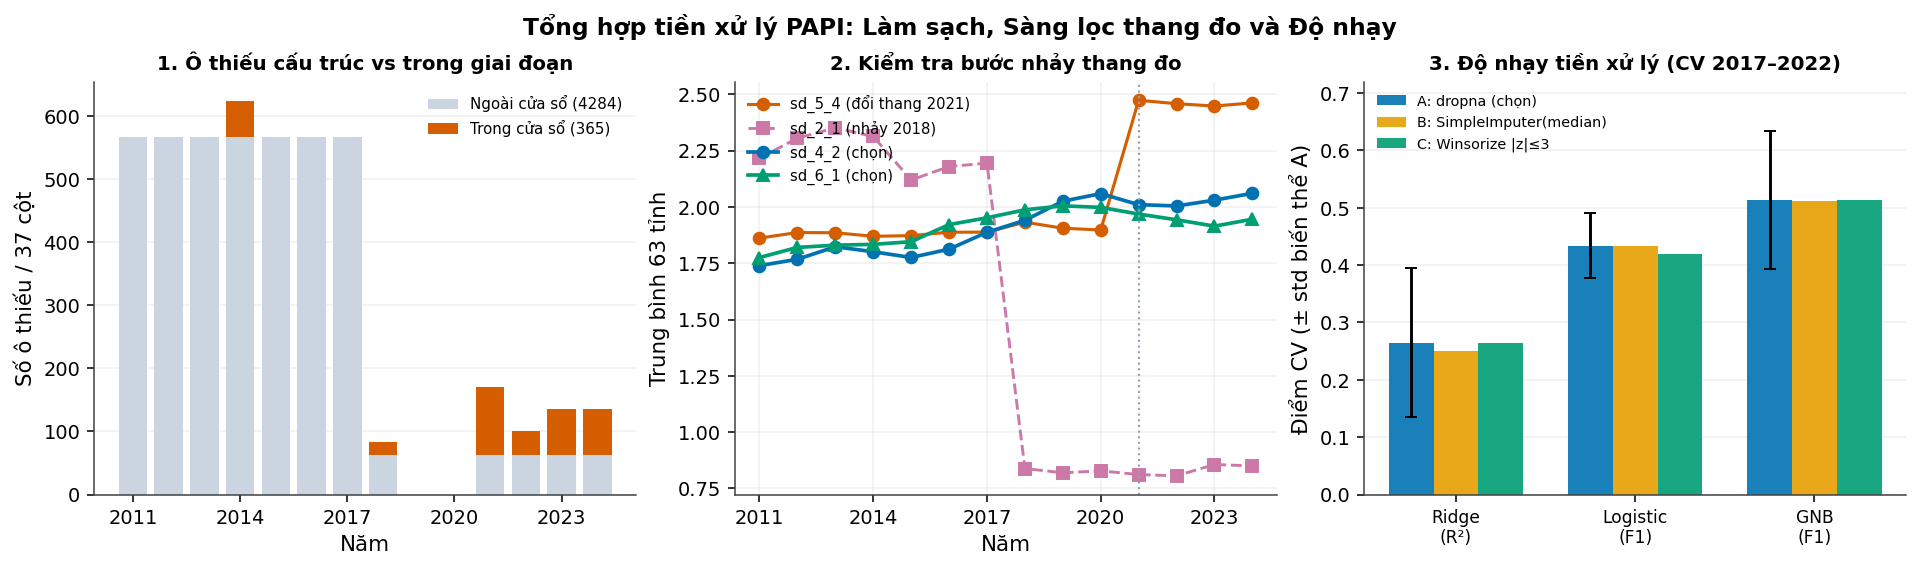

In [4]:
by_year = prep_state["missing_summary"]["by_year"]
yearly_means = panel.groupby("year")[["sd_5_4", "sd_2_1", "sd_4_2", "sd_6_1"]].mean()

with style_context():
    fig, (ax_m, ax_s, ax_cv) = plt.subplots(1, 3, figsize=(13.6, 3.95), dpi=140, layout="constrained")

    yrs = by_year["Năm"].to_numpy()
    s_miss = by_year["Thiếu cấu trúc (ngoài cửa sổ)"].to_numpy()
    w_miss = by_year["Thiếu trong cửa sổ"].to_numpy()
    ax_m.bar(yrs, s_miss, color="#CBD5E1", label=f"Ngoài cửa sổ ({int(s_miss.sum())})")
    ax_m.bar(yrs, w_miss, bottom=s_miss, color="#D55E00", label=f"Trong cửa sổ ({int(w_miss.sum())})")
    ax_m.set_title("1. Ô thiếu cấu trúc vs trong giai đoạn", fontsize=10.2)
    ax_m.set_xlabel("Năm")
    ax_m.set_ylabel("Số ô thiếu / 37 cột")
    ax_m.set_xticks(yrs[::3])
    ax_m.grid(axis="y", alpha=0.18)
    ax_m.legend(loc="upper right", fontsize=7.8, framealpha=0.92)

    ax_s.plot(yearly_means.index, yearly_means["sd_5_4"], "o-", color="#D55E00", lw=1.6, label="sd_5_4 (đổi thang 2021)")
    ax_s.plot(yearly_means.index, yearly_means["sd_2_1"], "s--", color=PALETTE["purple"], lw=1.5, label="sd_2_1 (nhảy 2018)")
    ax_s.plot(yearly_means.index, yearly_means["sd_4_2"], "o-", color=PALETTE["blue"], lw=1.9, label="sd_4_2 (chọn)")
    ax_s.plot(yearly_means.index, yearly_means["sd_6_1"], "^-", color=PALETTE["green"], lw=1.9, label="sd_6_1 (chọn)")
    ax_s.axvline(2021, color="#94A3B8", linestyle=":", lw=1.1)
    ax_s.set_title("2. Kiểm tra bước nhảy thang đo", fontsize=10.2)
    ax_s.set_xlabel("Năm")
    ax_s.set_ylabel("Trung bình 63 tỉnh")
    ax_s.set_xticks(yrs[::3])
    ax_s.grid(alpha=0.18)
    ax_s.legend(loc="upper left", fontsize=7.6, framealpha=0.92)

    models_order = [("regression", "ridge", "Ridge\n(R²)"), ("classification", "logistic regression", "Logistic\n(F1)"), ("classification", "gaussian naive bayes", "GNB\n(F1)")]
    x_m = np.arange(len(models_order))
    w_m = 0.25
    colors_v = {"A": PALETTE["blue"], "B": PALETTE["orange"], "C": PALETTE["green"]}
    labels_v = {"A": "A: dropna (chọn)", "B": "B: SimpleImputer(median)", "C": "C: Winsorize |z|≤3"}
    for idx_v, var in enumerate(("A", "B", "C")):
        vals = [float(sens.loc[(sens.task == t) & (sens.model == m) & (sens.variant == var), "value_cv"].iat[0]) for t, m, _ in models_order]
        errs = [float(sens.loc[(sens.task == t) & (sens.model == m) & (sens.variant == var), "cv_std"].iat[0]) for t, m, _ in models_order]
        ax_cv.bar(x_m + (idx_v - 1) * w_m, vals, width=w_m, color=colors_v[var], yerr=errs if var == "A" else None,
                  capsize=3, label=labels_v[var], alpha=0.9)
    ax_cv.set_xticks(x_m, [lbl for _, _, lbl in models_order], fontsize=8.8)
    ax_cv.set_ylim(0.0, 0.72)
    ax_cv.set_ylabel("Điểm CV (± std biến thể A)")
    ax_cv.set_title("3. Độ nhạy tiền xử lý (CV 2017–2022)", fontsize=10.2)
    ax_cv.grid(axis="y", alpha=0.18)
    ax_cv.legend(loc="upper left", fontsize=7.4, framealpha=0.92)
    fig.suptitle("Tổng hợp tiền xử lý PAPI: Làm sạch, Sàng lọc thang đo và Độ nhạy", fontsize=12.0)
    plt.show()

### 1.1 Phương pháp STING và kiểm chứng cài đặt

STING gốc [Wang, Yang & Muntz, VLDB 1997](https://www.vldb.org/conf/1997/P186.PDF)
lưu thống kê và loại phân phối của từng ô. Ở §5, tác giả chọn ô liên quan
từ tầng thô xuống tầng mịn và tìm vùng bằng BFS. Trong biến thể của nhóm,
`fit()` đưa điểm vào ô và tính thống kê theo từng tầng. `cluster()` giữ ô
đạt ngưỡng số đếm ở mức đã chọn, rồi dùng DFS để nối các ô dày chung cạnh.
`predict()` dùng lưới đã dựng để tra nhãn cho điểm mới.

ARI trên dữ liệu giả lập được đối chiếu với nhãn đã biết. Với PAPI, ARI giữa
các phương pháp biểu thị mức đồng thuận giữa các phân hoạch.

In [5]:
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sting import STING

X_synthetic, truth = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                               cluster_std=0.6, random_state=42)
synthetic = STING(n_levels=3, factor=4, min_count=3).fit(X_synthetic)
synthetic_labels = synthetic.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(truth, synthetic_labels)
assert ari >= 0.9
for cells_at_level in synthetic.cells_.values():
    assert sum(cell.count for cell in cells_at_level.values()) == len(truth)
print(f"Dữ liệu giả lập: ARI = {ari:.3f}, {synthetic.n_clusters_} cụm, "
      f"{(synthetic_labels == -1).mean():.1%} điểm nhiễu.")
print("Tổng số điểm được bảo toàn tại từng mức lưới.")

Dữ liệu giả lập: ARI = 0.950, 2 cụm, 2.5% điểm nhiễu.
Tổng số điểm được bảo toàn tại từng mức lưới.


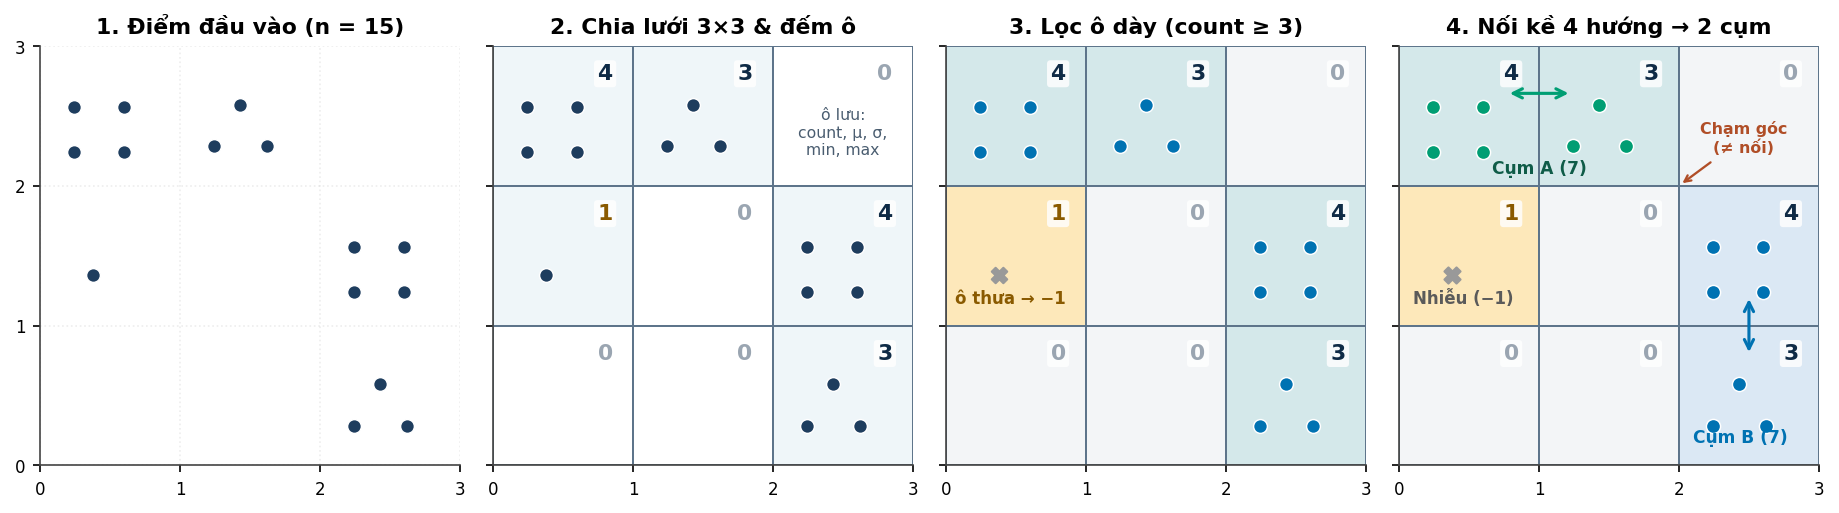

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Rectangle
from scripts.common.fig_style import PALETTE, style_context

_counts_demo = np.array([[4, 3, 0], [1, 0, 4], [0, 0, 3]])
_offsets_demo = {
    1: [(0.38, 0.36)],
    3: [(0.24, 0.28), (0.62, 0.28), (0.43, 0.58)],
    4: [(0.24, 0.24), (0.60, 0.24), (0.24, 0.56), (0.60, 0.56)],
}
_pts_d, _cells_d = [], []
for _r in range(3):
    _cy = 2 - _r
    for _c in range(3):
        _cnt = int(_counts_demo[_r, _c])
        for _dx, _dy in _offsets_demo.get(_cnt, ()):
            _pts_d.append((_c + _dx, _cy + _dy))
            _cells_d.append((_c, _cy))
_pts_d = np.asarray(_pts_d)
_step_titles = ("1. Điểm đầu vào (n = 15)", "2. Chia lưới 3×3 & đếm ô",
                "3. Lọc ô dày (count ≥ 3)", "4. Nối kề 4 hướng → 2 cụm")
with style_context():
    fig, axes = plt.subplots(1, 4, figsize=(12.2, 3.15), dpi=150, sharex=True, sharey=True, layout="constrained")
    for s_idx, (ax, s_title) in enumerate(zip(axes, _step_titles, strict=True)):
        ax.set_xlim(0.0, 3.0)
        ax.set_ylim(0.0, 3.0)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xticks([0, 1, 2, 3])
        ax.set_yticks([0, 1, 2, 3])
        ax.tick_params(labelsize=8)
        ax.set_title(s_title, fontsize=10.5, pad=6)
        if s_idx >= 1:
            for _r in range(3):
                _cy = 2 - _r
                for _c in range(3):
                    _cnt = int(_counts_demo[_r, _c])
                    if s_idx == 1:
                        _fill = "#EFF6F9" if _cnt > 0 else "#FFFFFF"
                    elif s_idx == 2:
                        _fill = "#D4E8EA" if _cnt >= 3 else ("#FDE8BA" if _cnt > 0 else "#F3F5F7")
                    else:
                        _fill = ("#D4E8EA" if (_c, _cy) in ((0, 2), (1, 2))
                                 else ("#DBE8F4" if (_c, _cy) in ((2, 1), (2, 0))
                                       else ("#FDE8BA" if _cnt > 0 else "#F3F5F7")))
                    ax.add_patch(Rectangle((_c, _cy), 1.0, 1.0, facecolor=_fill, edgecolor="#5D748A", linewidth=0.95))
                    _tcol = "#0F2B46" if _cnt >= 3 else ("#8A5A00" if _cnt > 0 else "#9AA5B1")
                    ax.text(_c + 0.80, _cy + 0.80, str(_cnt), ha="center", va="center", fontsize=10.5, fontweight="bold",
                            color=_tcol, bbox=dict(boxstyle="round,pad=0.16", fc="white", ec="none", alpha=0.82), zorder=3)
        else:
            ax.grid(alpha=0.22, linestyle=":")
        if s_idx < 3:
            if s_idx == 2:
                _dm = np.array([_counts_demo[2 - _cy, _cx] >= 3 for _cx, _cy in _cells_d])
                ax.scatter(_pts_d[_dm, 0], _pts_d[_dm, 1], s=44, color=PALETTE["blue"], edgecolors="white", linewidths=0.7, zorder=4)
                ax.scatter(_pts_d[~_dm, 0], _pts_d[~_dm, 1], s=55, color=PALETTE["gray"], marker="X", zorder=4)
                ax.text(0.46, 1.13, "ô thưa → −1", ha="center", va="bottom", fontsize=8, color="#8A5A00", fontweight="bold", zorder=5)
            else:
                ax.scatter(_pts_d[:, 0], _pts_d[:, 1], s=44, color="#1E3D5E", edgecolors="white", linewidths=0.7, zorder=4)
                if s_idx == 1:
                    ax.text(2.50, 2.38, "ô lưu:\ncount, μ, σ,\nmin, max", ha="center", va="center", fontsize=7.5, color="#4A5D70", zorder=4)
        else:
            _ga = np.array([tuple(c) in ((0, 2), (1, 2)) for c in _cells_d])
            _gb = np.array([tuple(c) in ((2, 1), (2, 0)) for c in _cells_d])
            _nm = ~(_ga | _gb)
            ax.scatter(_pts_d[_ga, 0], _pts_d[_ga, 1], s=46, color=PALETTE["green"], edgecolors="white", linewidths=0.7, zorder=4)
            ax.scatter(_pts_d[_gb, 0], _pts_d[_gb, 1], s=46, color=PALETTE["blue"], edgecolors="white", linewidths=0.7, zorder=4)
            ax.scatter(_pts_d[_nm, 0], _pts_d[_nm, 1], s=60, color=PALETTE["gray"], marker="X", zorder=5)
            for (_x0, _y0), (_x1, _y1), _ca in (((0.76, 2.66), (1.24, 2.66), PALETTE["green"]), ((2.50, 1.22), (2.50, 0.78), PALETTE["blue"])):
                ax.add_patch(FancyArrowPatch((_x0, _y0), (_x1, _y1), arrowstyle="<->", mutation_scale=11, linewidth=1.5, color=_ca, zorder=5))
            ax.text(1.00, 2.06, "Cụm A (7)", ha="center", va="bottom", fontsize=8.2, fontweight="bold", color="#0F5C48", zorder=5)
            ax.text(2.44, 0.14, "Cụm B (7)", ha="center", va="bottom", fontsize=8.2, fontweight="bold", color=PALETTE["blue"], zorder=5)
            ax.text(0.46, 1.13, "Nhiễu (−1)", ha="center", va="bottom", fontsize=8, fontweight="bold", color="#5A5A5A", zorder=5)
            ax.annotate("Chạm góc\n(≠ nối)", xy=(2.0, 2.0), xytext=(2.46, 2.34), ha="center", va="center",
                        fontsize=7.6, color="#B04E27", fontweight="bold", arrowprops=dict(arrowstyle="->", color="#B04E27", lw=1.1), zorder=5)
    plt.show()

In [7]:
features, params = cfg["features"], cfg["sting"]
train = panel[panel.year <= 2023].dropna(subset=features)
scaler = StandardScaler().fit(train[features])
train_scaled = scaler.transform(train[features])
sting = STING(n_levels=params["n_levels"], factor=params["factor"],
              min_count=params["min_count"]).fit(train_scaled)
train_labels = sting.cluster(level=params["cluster_level"], connectivity=params["connectivity"])
eligible = panel.dropna(subset=features)
scaled = scaler.transform(eligible[features])
rebuilt = eligible[["province_code", "year"]].assign(pred_cluster=sting.predict(scaled))
saved = pd.read_csv(ROOT / "results/predict_all_years.csv")
comparison = rebuilt.merge(saved, on=["province_code", "year"],
                           suffixes=("_rebuilt", "_saved"), validate="one_to_one")
assert len(comparison) == len(saved) == len(eligible)
np.testing.assert_array_equal(comparison.pred_cluster_rebuilt, comparison.pred_cluster_saved)
loaded = STING.load(ROOT / "models/sting_predict_model.pkl")
scale_info = json.loads((ROOT / "models/sting_predict_scaler.json").read_text(encoding="utf-8"))
loaded_scaled = (eligible[features].to_numpy() - np.array(scale_info["mean"])) / np.array(scale_info["scale"])
np.testing.assert_array_equal(loaded.predict(loaded_scaled), rebuilt.pred_cluster.to_numpy())
test = rebuilt[rebuilt.year == 2024]
print(f"Tái lập STING: {len(comparison)}/{len(saved)} nhãn khớp với kết quả đã lưu.")
print("Mô hình đã lưu và mô hình dựng lại cho cùng nhãn.")
test_noise = int(test.pred_cluster.eq(-1).sum())
print(f"Năm 2024: {len(test)}/63 tỉnh đủ hai chỉ tiêu. "
      f"{len(test) - test_noise} tỉnh được gán cụm, {test_noise} tỉnh nhận nhãn nhiễu.")
train_z_flag = (np.abs(train_scaled) > 3).any(axis=1)
train_noise = int((train_labels == -1).sum())
train_sparse_no_flag = int(((train_labels == -1) & ~train_z_flag).sum())
trimmed_sting = STING(n_levels=params["n_levels"], factor=params["factor"],
                      min_count=params["min_count"]).fit(train_scaled[~train_z_flag])
trimmed_train_labels = trimmed_sting.cluster(level=params["cluster_level"],
                                             connectivity=params["connectivity"])
trimmed_train_noise = int((trimmed_train_labels == -1).sum())
print(f"2011–2023: {train_z_flag.sum()} quan sát có |z| > 3; "
      f"{train_sparse_no_flag}/{train_noise} điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.")
print(f"Nếu loại {train_z_flag.sum()} điểm |z| > 3 rồi dựng lại lưới trên {len(trimmed_train_labels)} điểm: "
      f"{trimmed_sting.n_clusters_} cụm, {trimmed_train_noise}/{len(trimmed_train_labels)} điểm nhiễu "
      f"({trimmed_train_noise / len(trimmed_train_labels):.1%}).")

Tái lập STING: 869/869 nhãn khớp với kết quả đã lưu.
Mô hình đã lưu và mô hình dựng lại cho cùng nhãn.
Năm 2024: 61/63 tỉnh đủ hai chỉ tiêu. 48 tỉnh được gán cụm, 13 tỉnh nhận nhãn nhiễu.
2011–2023: 7 quan sát có |z| > 3; 151/158 điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.
Nếu loại 7 điểm |z| > 3 rồi dựng lại lưới trên 801 điểm: 4 cụm, 197/801 điểm nhiễu (24.6%).


Đổi kề 8 hướng (connectivity=2) trên 2011–2023: 56 ô dày → 1 cụm, 158/808 điểm nhiễu (19.6%).


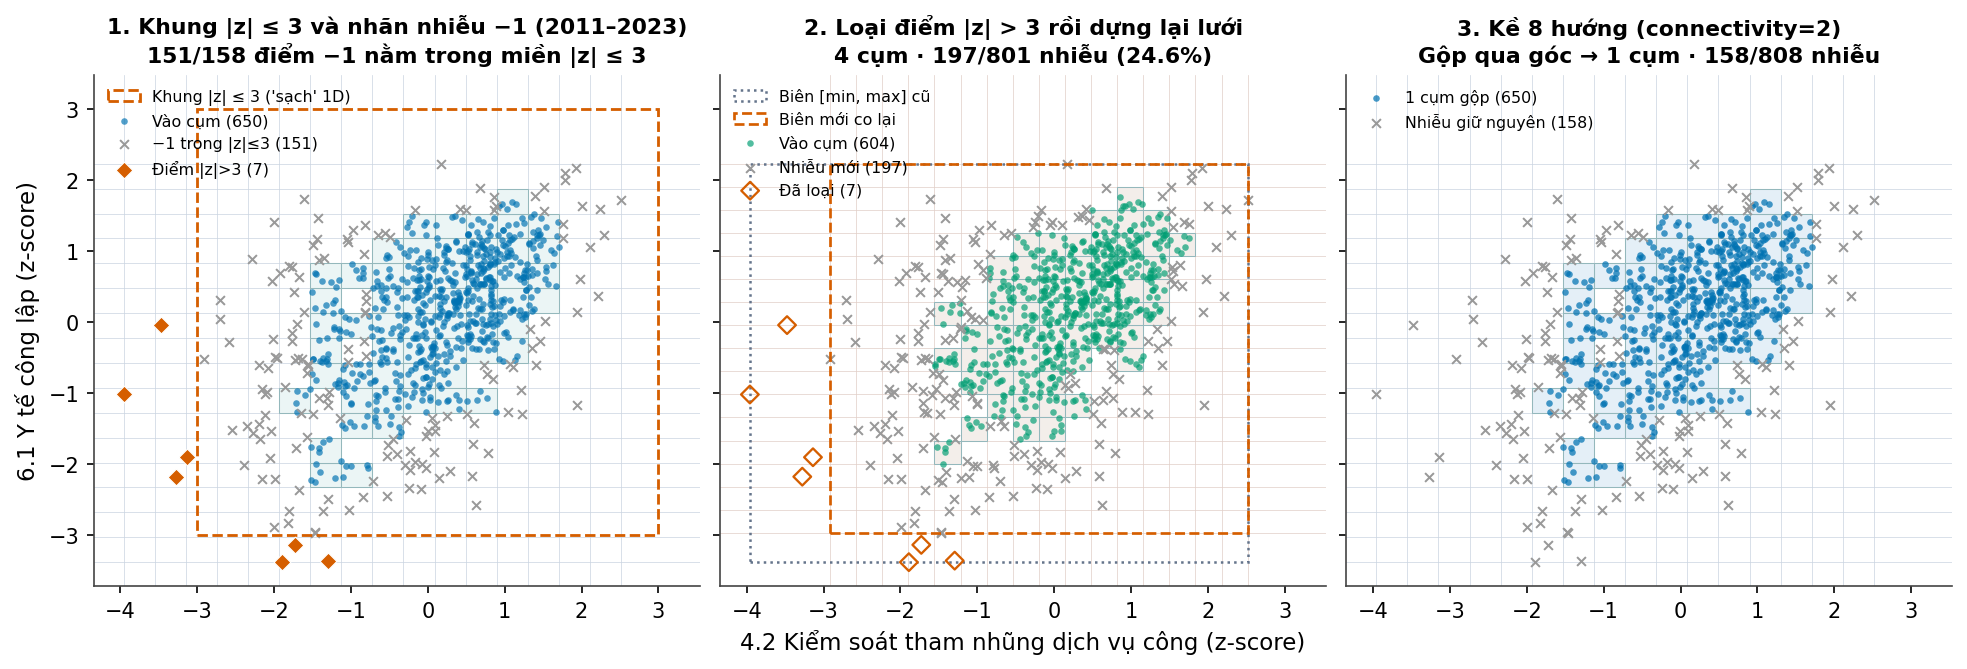

In [8]:
import copy

conn8_sting = copy.deepcopy(sting)
conn8_labels = conn8_sting.cluster(level=params["cluster_level"], connectivity=2)
conn8_noise = int((conn8_labels == -1).sum())
print(f"Đổi kề 8 hướng (connectivity=2) trên 2011–2023: {len(conn8_sting.label_of_)} ô dày → "
      f"{conn8_sting.n_clusters_} cụm, {conn8_noise}/{len(conn8_labels)} điểm nhiễu ({conn8_noise / len(conn8_labels):.1%}).")

def _draw_sting_grid(ax, m, *, grid_color="#CBD5E1", dense_fill="#EBF5F5"):
    res = m.factor ** m.cluster_level_
    b_lo, b_hi = m.bounds_min_, m.bounds_max_
    step = (b_hi - b_lo) / res
    for idx in m.label_of_:
        cell = m.cells_[m.cluster_level_][idx]
        ax.add_patch(Rectangle(cell.bounds_min, *(cell.bounds_max - cell.bounds_min),
                               facecolor=dense_fill, edgecolor="#94B8BC", linewidth=0.5, zorder=1))
    for i in range(res + 1):
        ax.axvline(b_lo[0] + i * step[0], color=grid_color, linewidth=0.35, zorder=0.5)
        ax.axhline(b_lo[1] + i * step[1], color=grid_color, linewidth=0.35, zorder=0.5)

_lo_t, _hi_t = sting.bounds_min_, sting.bounds_max_
_px_t, _py_t = (_hi_t[0] - _lo_t[0]) * 0.06, (_hi_t[1] - _lo_t[1]) * 0.06
with style_context():
    fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.35), dpi=150, sharex=True, sharey=True, layout="constrained")

    _draw_sting_grid(axes[0], sting)
    axes[0].add_patch(Rectangle((-3.0, -3.0), 6.0, 6.0, facecolor="none", edgecolor="#D55E00",
                                linestyle="--", linewidth=1.35, label="Khung |z| ≤ 3 ('sạch' 1D)", zorder=4))
    _nm = train_labels == -1
    _sc = _nm & ~train_z_flag
    axes[0].scatter(train_scaled[~_nm, 0], train_scaled[~_nm, 1], s=10, color=PALETTE["blue"], alpha=0.68, linewidths=0,
                    label=f"Vào cụm ({int((~_nm).sum())})", zorder=2)
    axes[0].scatter(train_scaled[_sc, 0], train_scaled[_sc, 1], s=18, color=PALETTE["gray"], marker="x", linewidths=0.95,
                    label=f"−1 trong |z|≤3 ({train_sparse_no_flag})", zorder=3)
    axes[0].scatter(train_scaled[train_z_flag, 0], train_scaled[train_z_flag, 1], s=32, color="#D55E00", marker="D",
                    edgecolors="white", linewidths=0.5, label=f"Điểm |z|>3 ({int(train_z_flag.sum())})", zorder=5)
    axes[0].set_title(f"1. Khung |z| ≤ 3 và nhãn nhiễu −1 (2011–2023)\n{train_sparse_no_flag}/{train_noise} điểm −1 nằm trong miền |z| ≤ 3", fontsize=10.5)
    axes[0].set_ylabel("6.1 Y tế công lập (z-score)")
    axes[0].legend(loc="upper left", fontsize=7.6, framealpha=0.92)


    _draw_sting_grid(axes[1], trimmed_sting, grid_color="#E2CFC9", dense_fill="#F3EEEA")
    axes[1].add_patch(Rectangle(_lo_t, *(_hi_t - _lo_t), facecolor="none", edgecolor="#64748B",
                                linestyle=":", linewidth=1.2, label="Biên [min, max] cũ", zorder=3))
    axes[1].add_patch(Rectangle(trimmed_sting.bounds_min_, *(trimmed_sting.bounds_max_ - trimmed_sting.bounds_min_),
                                facecolor="none", edgecolor="#D55E00", linestyle="--", linewidth=1.3, label="Biên mới co lại", zorder=4))
    _kept = train_scaled[~train_z_flag]
    _ta = trimmed_train_labels >= 0
    axes[1].scatter(_kept[_ta, 0], _kept[_ta, 1], s=10, color=PALETTE["green"], alpha=0.68, linewidths=0,
                    label=f"Vào cụm ({int(_ta.sum())})", zorder=2)
    axes[1].scatter(_kept[~_ta, 0], _kept[~_ta, 1], s=18, color=PALETTE["gray"], marker="x", linewidths=0.95,
                    label=f"Nhiễu mới ({trimmed_train_noise})", zorder=3)
    axes[1].scatter(train_scaled[train_z_flag, 0], train_scaled[train_z_flag, 1], s=36, facecolors="none", edgecolors="#D55E00",
                    marker="D", linewidths=1.1, label=f"Đã loại ({int(train_z_flag.sum())})", zorder=5)
    axes[1].set_title(f"2. Loại điểm |z| > 3 rồi dựng lại lưới\n{trimmed_sting.n_clusters_} cụm · {trimmed_train_noise}/{len(trimmed_train_labels)} nhiễu ({trimmed_train_noise / len(trimmed_train_labels):.1%})", fontsize=10.5)
    axes[1].set_xlabel("4.2 Kiểm soát tham nhũng dịch vụ công (z-score)")
    axes[1].legend(loc="upper left", fontsize=7.6, framealpha=0.92)


    _draw_sting_grid(axes[2], conn8_sting, dense_fill="#E4EFF7")
    _c8a = conn8_labels >= 0
    axes[2].scatter(train_scaled[_c8a, 0], train_scaled[_c8a, 1], s=10, color=PALETTE["blue"], alpha=0.72, linewidths=0,
                    label=f"1 cụm gộp ({int(_c8a.sum())})", zorder=2)
    axes[2].scatter(train_scaled[~_c8a, 0], train_scaled[~_c8a, 1], s=18, color=PALETTE["gray"], marker="x", linewidths=0.95,
                    label=f"Nhiễu giữ nguyên ({conn8_noise})", zorder=3)
    axes[2].set_title(f"3. Kề 8 hướng (connectivity=2)\nGộp qua góc → {conn8_sting.n_clusters_} cụm · {conn8_noise}/{len(conn8_labels)} nhiễu", fontsize=10.5)
    axes[2].legend(loc="upper left", fontsize=7.6, framealpha=0.92)

    axes[0].set_xlim(min(_lo_t[0], -3.15) - _px_t, max(_hi_t[0], 3.15) + _px_t)
    axes[0].set_ylim(min(_lo_t[1], -3.15) - _py_t, max(_hi_t[1], 3.15) + _py_t)
    plt.show()

### 1.2 Lưới STING trên PAPI

Hình dưới cho thấy ba mức lưới của cấu hình đóng băng (`factor=4`, `min_count=5`).
Mức 0 là một ô chứa toàn bộ điểm. Mức 1 chia mỗi chiều thành 4 đoạn và ghi số điểm
trong từng ô. Mức 2 chia thành 16 đoạn; các ô có ít nhất 5 điểm là ô dày, các ô dày
kề mặt được gom thành cụm, điểm ở ô còn lại là nhiễu.

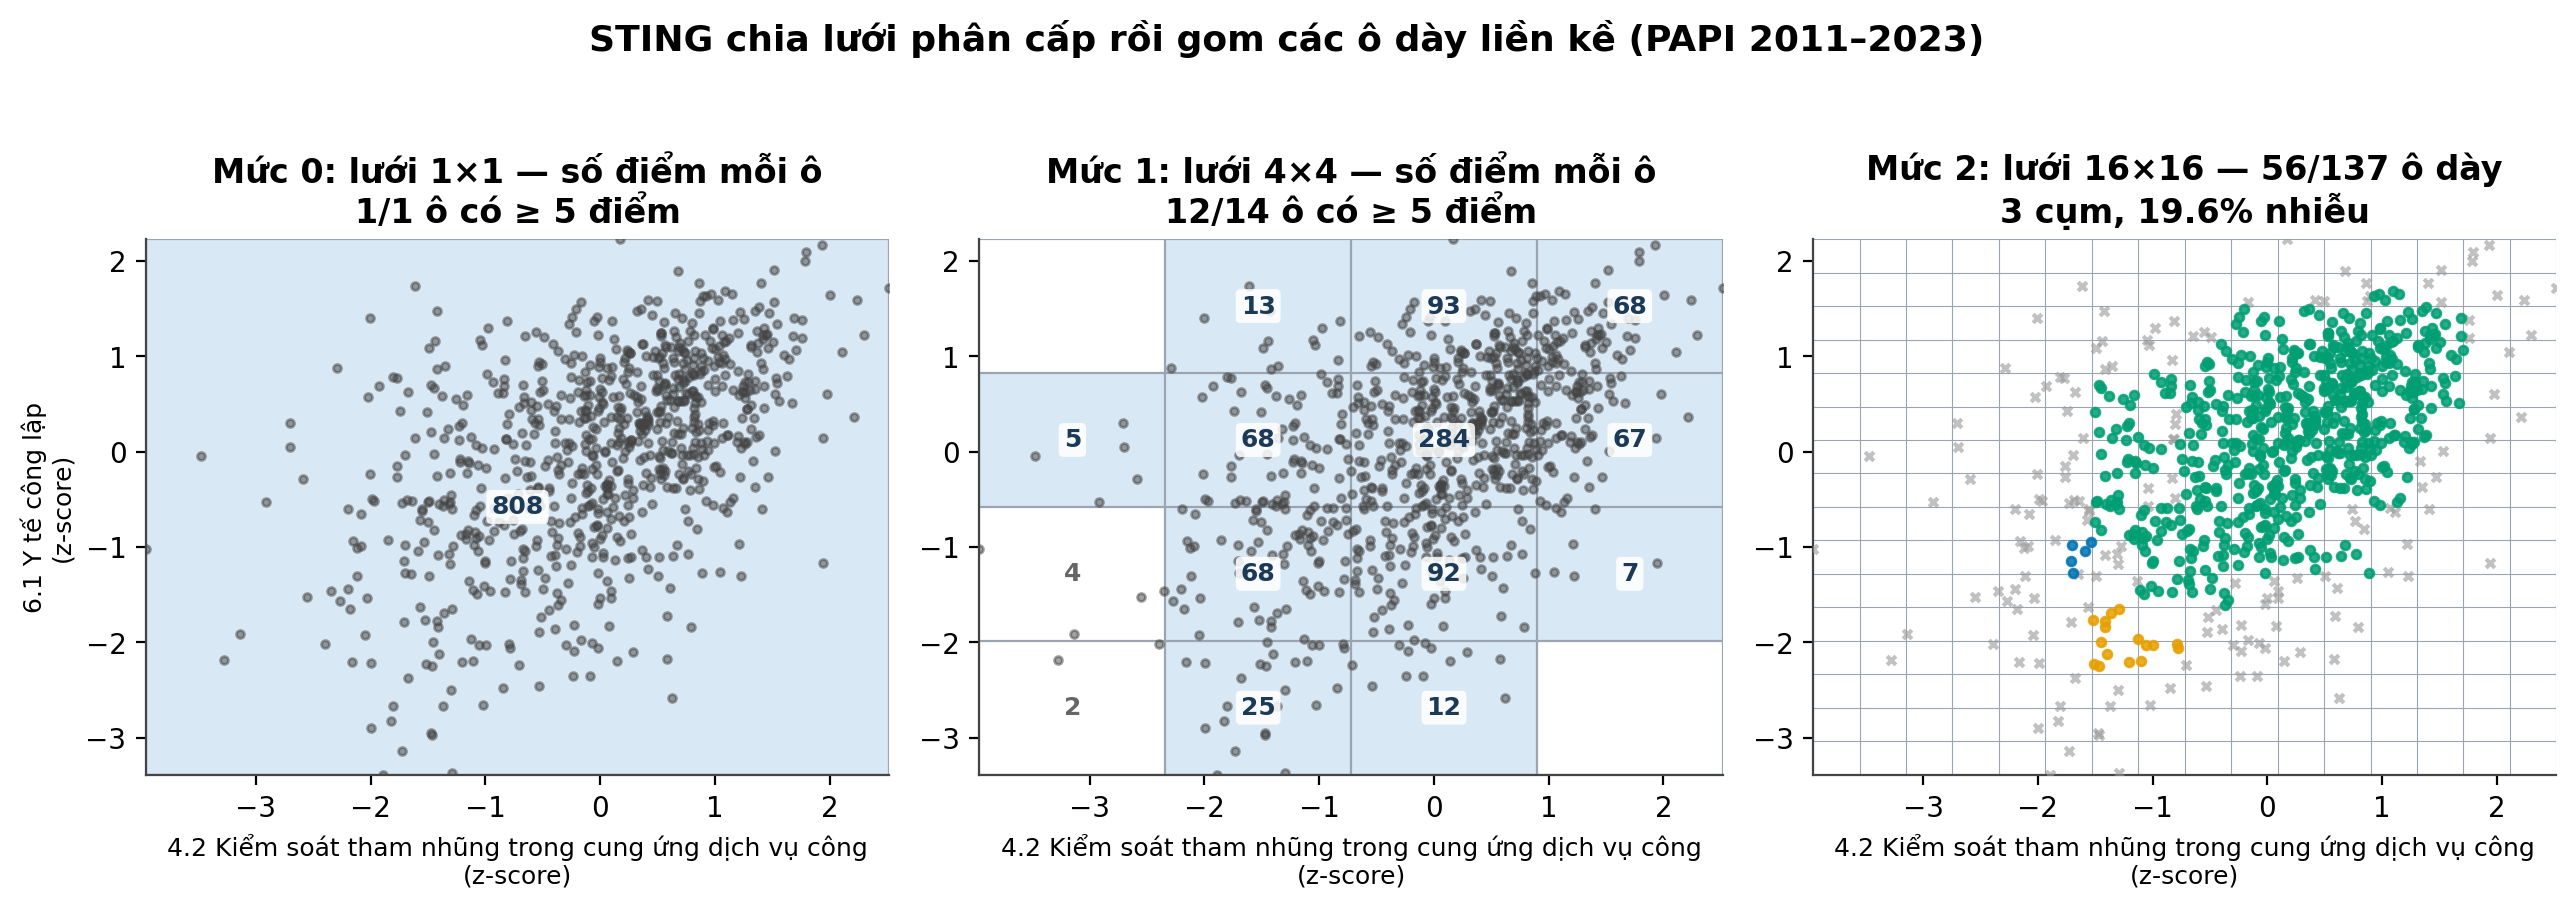

Truy vấn top-down trên lưới PAPI 2011–2023 [0; 2,5]²: khớp 277 điểm (μ = [0.838 0.836]), duyệt 68/152 ô có dữ liệu, tỉa bỏ 34 nhánh.


In [9]:
display(Image(filename=str(ROOT / "results/figs/sting_grid_levels.png")))

rect_hi = [(0.0, 2.5), (0.0, 2.5)]
q_rect_808 = sting.query_rect(rect_hi, level=2)
q_td_808 = sting.query_top_down(rect_hi, confidence=0.95, level=2)
assert q_td_808["count"] == q_rect_808["count"]
np.testing.assert_allclose(q_td_808["mean"], q_rect_808["mean"])
occ_808 = sum(len(sting.cells_[lvl]) for lvl in range(sting.n_levels))
print(
    f"Truy vấn top-down trên lưới PAPI 2011–2023 [0; 2,5]²: khớp {q_td_808['count']} điểm "
    f"(μ = {q_td_808['mean'].round(3)}), duyệt {q_td_808['visited_cells']}/{occ_808} ô có dữ liệu, "
    f"tỉa bỏ {q_td_808['pruned_cells']} nhánh."
)

## 2. So sánh STING, K-means và DBSCAN trên PAPI 2011–2023

Silhouette, Davies–Bouldin và Calinski–Harabasz được tính trên các điểm thuộc cụm.

In [10]:
metrics = pd.read_csv(ROOT / "results/metrics.csv")
show_md(metrics[metrics.scope == "pooled 2011-2023"].to_markdown(index=False))

| scope            | method         |   k |   noise_ratio |   silhouette |   davies_bouldin |   calinski_harabasz |   ari_vs_sting | note                                             |
|:-----------------|:---------------|----:|--------------:|-------------:|-----------------:|--------------------:|---------------:|:-------------------------------------------------|
| pooled 2011-2023 | STING (frozen) |   3 |         0.196 |        0.361 |            0.472 |                62   |        nan     | k=3: [629,16,5]; noise tách khỏi metric hình học |
| pooled 2011-2023 | k-means k=2    |   2 |         0     |        0.445 |            0.876 |               812.3 |          0.166 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=3    |   3 |         0     |        0.336 |            1.05  |               665.7 |          0.139 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=4    |   4 |         0     |        0.364 |            0.879 |               669.1 |          0.082 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=5    |   5 |         0     |        0.334 |            0.945 |               647.9 |          0.07  | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | DBSCAN eps=0.2 |   5 |         0.142 |        0.218 |            0.505 |                35.3 |          0.647 | nan                                              |
| pooled 2011-2023 | DBSCAN eps=0.4 |   1 |         0.027 |      nan     |          nan     |               nan   |          0.135 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.6 |   1 |         0.009 |      nan     |          nan     |               nan   |          0.043 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.8 |   1 |         0.002 |      nan     |          nan     |               nan   |          0.012 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=1.0 |   1 |         0.001 |      nan     |          nan     |               nan   |          0.006 | metric n/a khi <2 cụm                            |

### Chọn k cho K-means đối chứng

K-means cần chọn trước số cụm k. Hình dưới vẽ WCSS (tổng bình phương khoảng cách
trong cụm) và silhouette theo k trên cùng hai chỉ tiêu đã chuẩn hóa. WCSS giảm
dần, không có khuỷu rõ rệt. Silhouette cao nhất tại k = 2 (0,445), nên đối chứng
dùng k = 2.

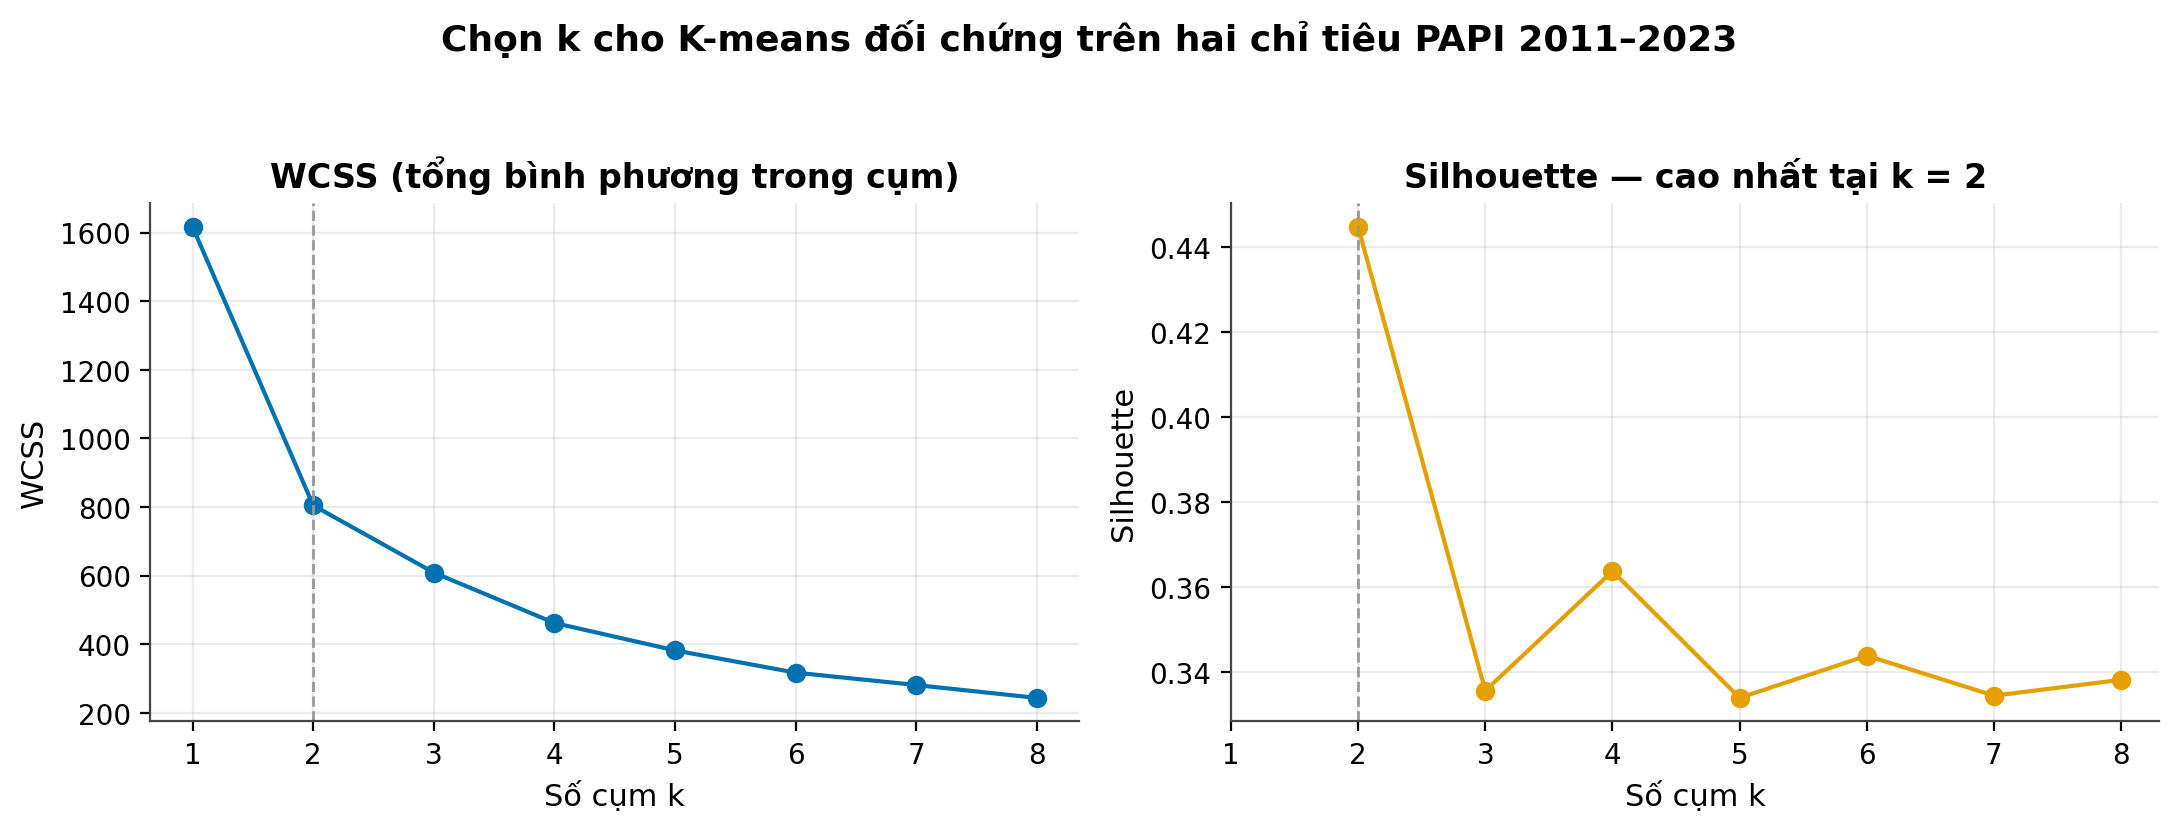

In [11]:
display(Image(filename=str(ROOT / "results/figs/kmeans_elbow.png")))

### Kết quả so sánh

STING tạo một cụm 629 điểm, hai cụm nhỏ 16 và 5 điểm, với 19,6% nhiễu.
Để đọc kết quả trên cùng số quan sát, nhóm dùng giao các điểm mà cả STING
và DBSCAN đều gán vào cụm. Giữ nhãn từ phân hoạch đã học trên 808 quan sát
và tính lại silhouette trên tập giao. K-means gán nhãn cho cả 808 điểm nên
cũng có nhãn trên toàn bộ tập giao.

In [12]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score

kmeans_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(train_scaled)
dbscan_labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(train_scaled)
shared = (train_labels >= 0) & (dbscan_labels >= 0)
comparison_rows = []
models = [
    ("STING", "STING (frozen)", train_labels),
    ("K-means (k=2)", "k-means k=2", kmeans_labels),
    ("DBSCAN (eps=0,2)", "DBSCAN eps=0.2", dbscan_labels),
]
reference = metrics[metrics.scope == "pooled 2011-2023"].set_index("method")
for label, key, labels in models:
    assigned = labels >= 0
    score = silhouette_score(train_scaled[assigned], labels[assigned])
    score_shared = silhouette_score(train_scaled[shared], labels[shared])
    assert abs(score - reference.loc[key, "silhouette"]) <= 0.0005
    comparison_rows.append((label, int(assigned.sum()), f"{score:.3f}", f"{score_shared:.3f}"))
shared_table = pd.DataFrame(comparison_rows, columns=[
    "Phương pháp", "Điểm thuộc cụm", "Silhouette trên tập riêng", "Silhouette trên tập giao",
])
print(f"Tập giao có {shared.sum()}/{len(train_scaled)} quan sát.")
show_md(shared_table.to_markdown(index=False))
ari_all = adjusted_rand_score(train_labels, dbscan_labels)
ari_shared = adjusted_rand_score(train_labels[shared], dbscan_labels[shared])
assert abs(ari_all - reference.loc["DBSCAN eps=0.2", "ari_vs_sting"]) <= 0.0005
print(f"ARI STING–DBSCAN trên toàn bộ mẫu (gồm nhãn nhiễu): {ari_all:.3f}.")
print(f"ARI STING–DBSCAN trên tập giao các điểm thuộc cụm: {ari_shared:.3f}.")

Tập giao có 631/808 quan sát.


| Phương pháp      |   Điểm thuộc cụm |   Silhouette trên tập riêng |   Silhouette trên tập giao |
|:-----------------|-----------------:|----------------------------:|---------------------------:|
| STING            |              650 |                       0.361 |                      0.366 |
| K-means (k=2)    |              808 |                       0.445 |                      0.457 |
| DBSCAN (eps=0,2) |              693 |                       0.218 |                      0.258 |

ARI STING–DBSCAN trên toàn bộ mẫu (gồm nhãn nhiễu): 0.647.
ARI STING–DBSCAN trên tập giao các điểm thuộc cụm: 0.431.


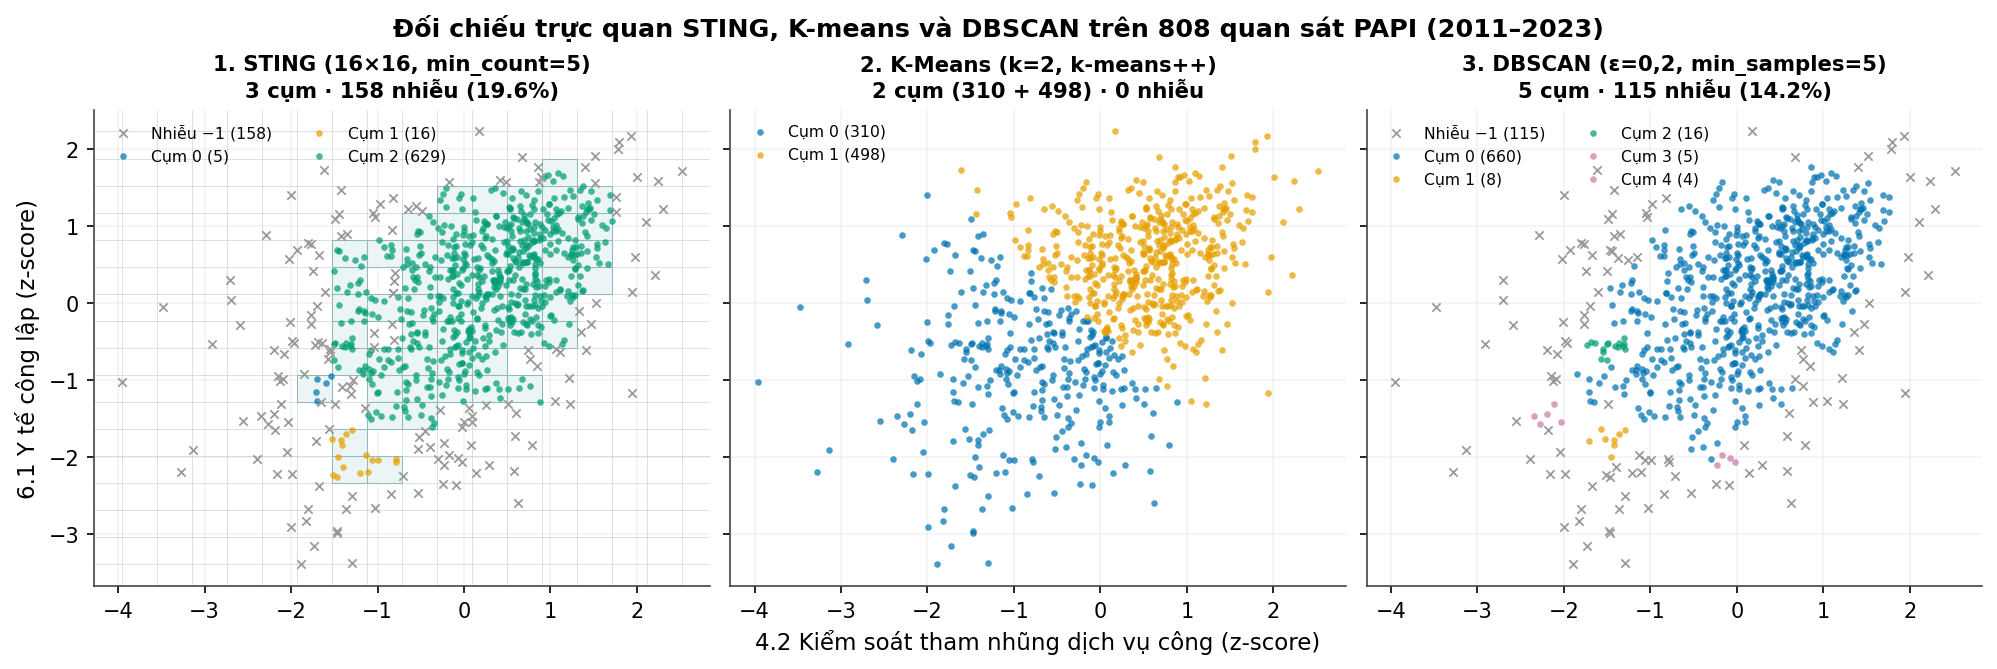

In [13]:
from scripts.common.fig_style import CLUSTER_COLORS

with style_context():
    fig_cmp, axes_cmp = plt.subplots(1, 3, figsize=(13.2, 4.35), dpi=150, sharex=True, sharey=True, layout="constrained")
    n_db_clusters = len(set(dbscan_labels[dbscan_labels >= 0]))
    cmp_specs = (
        (axes_cmp[0], train_labels, f"1. STING (16×16, min_count=5)\n{sting.n_clusters_} cụm · {int((train_labels == -1).sum())} nhiễu ({(train_labels == -1).mean():.1%})"),
        (axes_cmp[1], kmeans_labels, f"2. K-Means (k=2, k-means++)\n2 cụm ({int((kmeans_labels == 0).sum())} + {int((kmeans_labels == 1).sum())}) · 0 nhiễu"),
        (axes_cmp[2], dbscan_labels, f"3. DBSCAN (ε=0,2, min_samples=5)\n{n_db_clusters} cụm · {int((dbscan_labels == -1).sum())} nhiễu ({(dbscan_labels == -1).mean():.1%})"),
    )
    for ax_c, lbls_c, ttl_c in cmp_specs:
        if ax_c is axes_cmp[0]:
            _draw_sting_grid(ax_c, sting)
        ns_c = lbls_c == -1
        if np.any(ns_c):
            ax_c.scatter(train_scaled[ns_c, 0], train_scaled[ns_c, 1], s=16, color=PALETTE["gray"],
                         marker="x", linewidths=0.85, label=f"Nhiễu −1 ({int(ns_c.sum())})", zorder=2.5)
        for cid_c in sorted(set(lbls_c[lbls_c >= 0])):
            mk_c = lbls_c == cid_c
            ax_c.scatter(train_scaled[mk_c, 0], train_scaled[mk_c, 1], s=10,
                         color=CLUSTER_COLORS.get(cid_c, PALETTE["purple"]), alpha=0.72, linewidths=0,
                         label=f"Cụm {cid_c} ({int(mk_c.sum())})", zorder=2.2)
        ax_c.set_title(ttl_c, fontsize=10.2)
        ax_c.grid(alpha=0.14)
        ax_c.legend(loc="upper left", fontsize=7.5, framealpha=0.92, ncols=2 if cid_c >= 2 or np.any(ns_c) else 1)
    axes_cmp[0].set_ylabel("6.1 Y tế công lập (z-score)")
    axes_cmp[1].set_xlabel("4.2 Kiểm soát tham nhũng dịch vụ công (z-score)")
    fig_cmp.suptitle("Đối chiếu trực quan STING, K-means và DBSCAN trên 808 quan sát PAPI (2011–2023)", fontsize=12.2)
    plt.show()

## 3. STING theo từng năm

In [14]:
per_year = pd.read_csv(ROOT / "results/per_year.csv")
show_md(per_year.to_markdown(index=False))
print()
single_cluster_years = per_year["k"].eq(1).sum()
print(f"{single_cluster_years}/{len(per_year)} năm có một cụm với lưới 3 × 3 và min_count=3.")

|   year |   n |   k |   noise_ratio | cluster_sizes   |
|-------:|----:|----:|--------------:|:----------------|
|   2011 |  63 |   1 |         0.063 | [59]            |
|   2012 |  63 |   1 |         0     | [63]            |
|   2013 |  63 |   1 |         0.048 | [60]            |
|   2014 |  61 |   1 |         0.016 | [60]            |
|   2015 |  63 |   1 |         0.032 | [61]            |
|   2016 |  63 |   1 |         0.032 | [61]            |
|   2017 |  63 |   1 |         0.063 | [59]            |
|   2018 |  61 |   1 |         0.049 | [58]            |
|   2019 |  63 |   1 |         0.016 | [62]            |
|   2020 |  63 |   1 |         0.063 | [59]            |
|   2021 |  60 |   1 |         0.067 | [56]            |
|   2022 |  61 |   1 |         0.033 | [59]            |
|   2023 |  61 |   1 |         0     | [61]            |
|   2024 |  61 |   1 |         0.049 | [58]            |


14/14 năm có một cụm với lưới 3 × 3 và min_count=3.


## 4. Đối chiếu PAPI năm 2024 trên lưới đến năm 2023

Dựng lưới từ 2011–2023 để gán nhãn cho điểm PAPI đã quan sát năm 2024.
Trong 61 tỉnh đủ hai chỉ tiêu, có 48 tỉnh vào cụm lớn và 13 tỉnh nhận nhãn
nhiễu. Hai tỉnh thiếu chỉ tiêu được để trống. Bảng chuyển trạng thái dưới
đây chỉ dùng các tỉnh đủ dữ liệu ở cả hai năm.

In [15]:
paired = (rebuilt[rebuilt.year.isin([2023, 2024])]
          .pivot(index="province_code", columns="year", values="pred_cluster")
          .dropna().astype(int))
main_cluster = int(pd.Series(train_labels[train_labels >= 0]).mode().iat[0])
label_names = {main_cluster: "Cụm lớn", -1: "Nhiễu"}
transition = pd.crosstab(paired[2023], paired[2024], rownames=["Năm 2023"],
                         colnames=["Năm 2024"])
transition = transition.rename(index=label_names, columns=label_names)
print(f"Đối chiếu trên {len(paired)} tỉnh đủ dữ liệu ở cả hai năm.")
show_md(transition.to_markdown())
print(f"{transition.loc['Cụm lớn', 'Nhiễu']} tỉnh từ cụm lớn sang nhiễu.")
print(f"{transition.loc['Nhiễu', 'Cụm lớn']} tỉnh từ nhiễu vào cụm lớn.")

Đối chiếu trên 59 tỉnh đủ dữ liệu ở cả hai năm.


| Năm 2023   |   Nhiễu |   Cụm lớn |
|:-----------|--------:|----------:|
| Nhiễu      |       4 |         5 |
| Cụm lớn    |       7 |        43 |

7 tỉnh từ cụm lớn sang nhiễu.
5 tỉnh từ nhiễu vào cụm lớn.


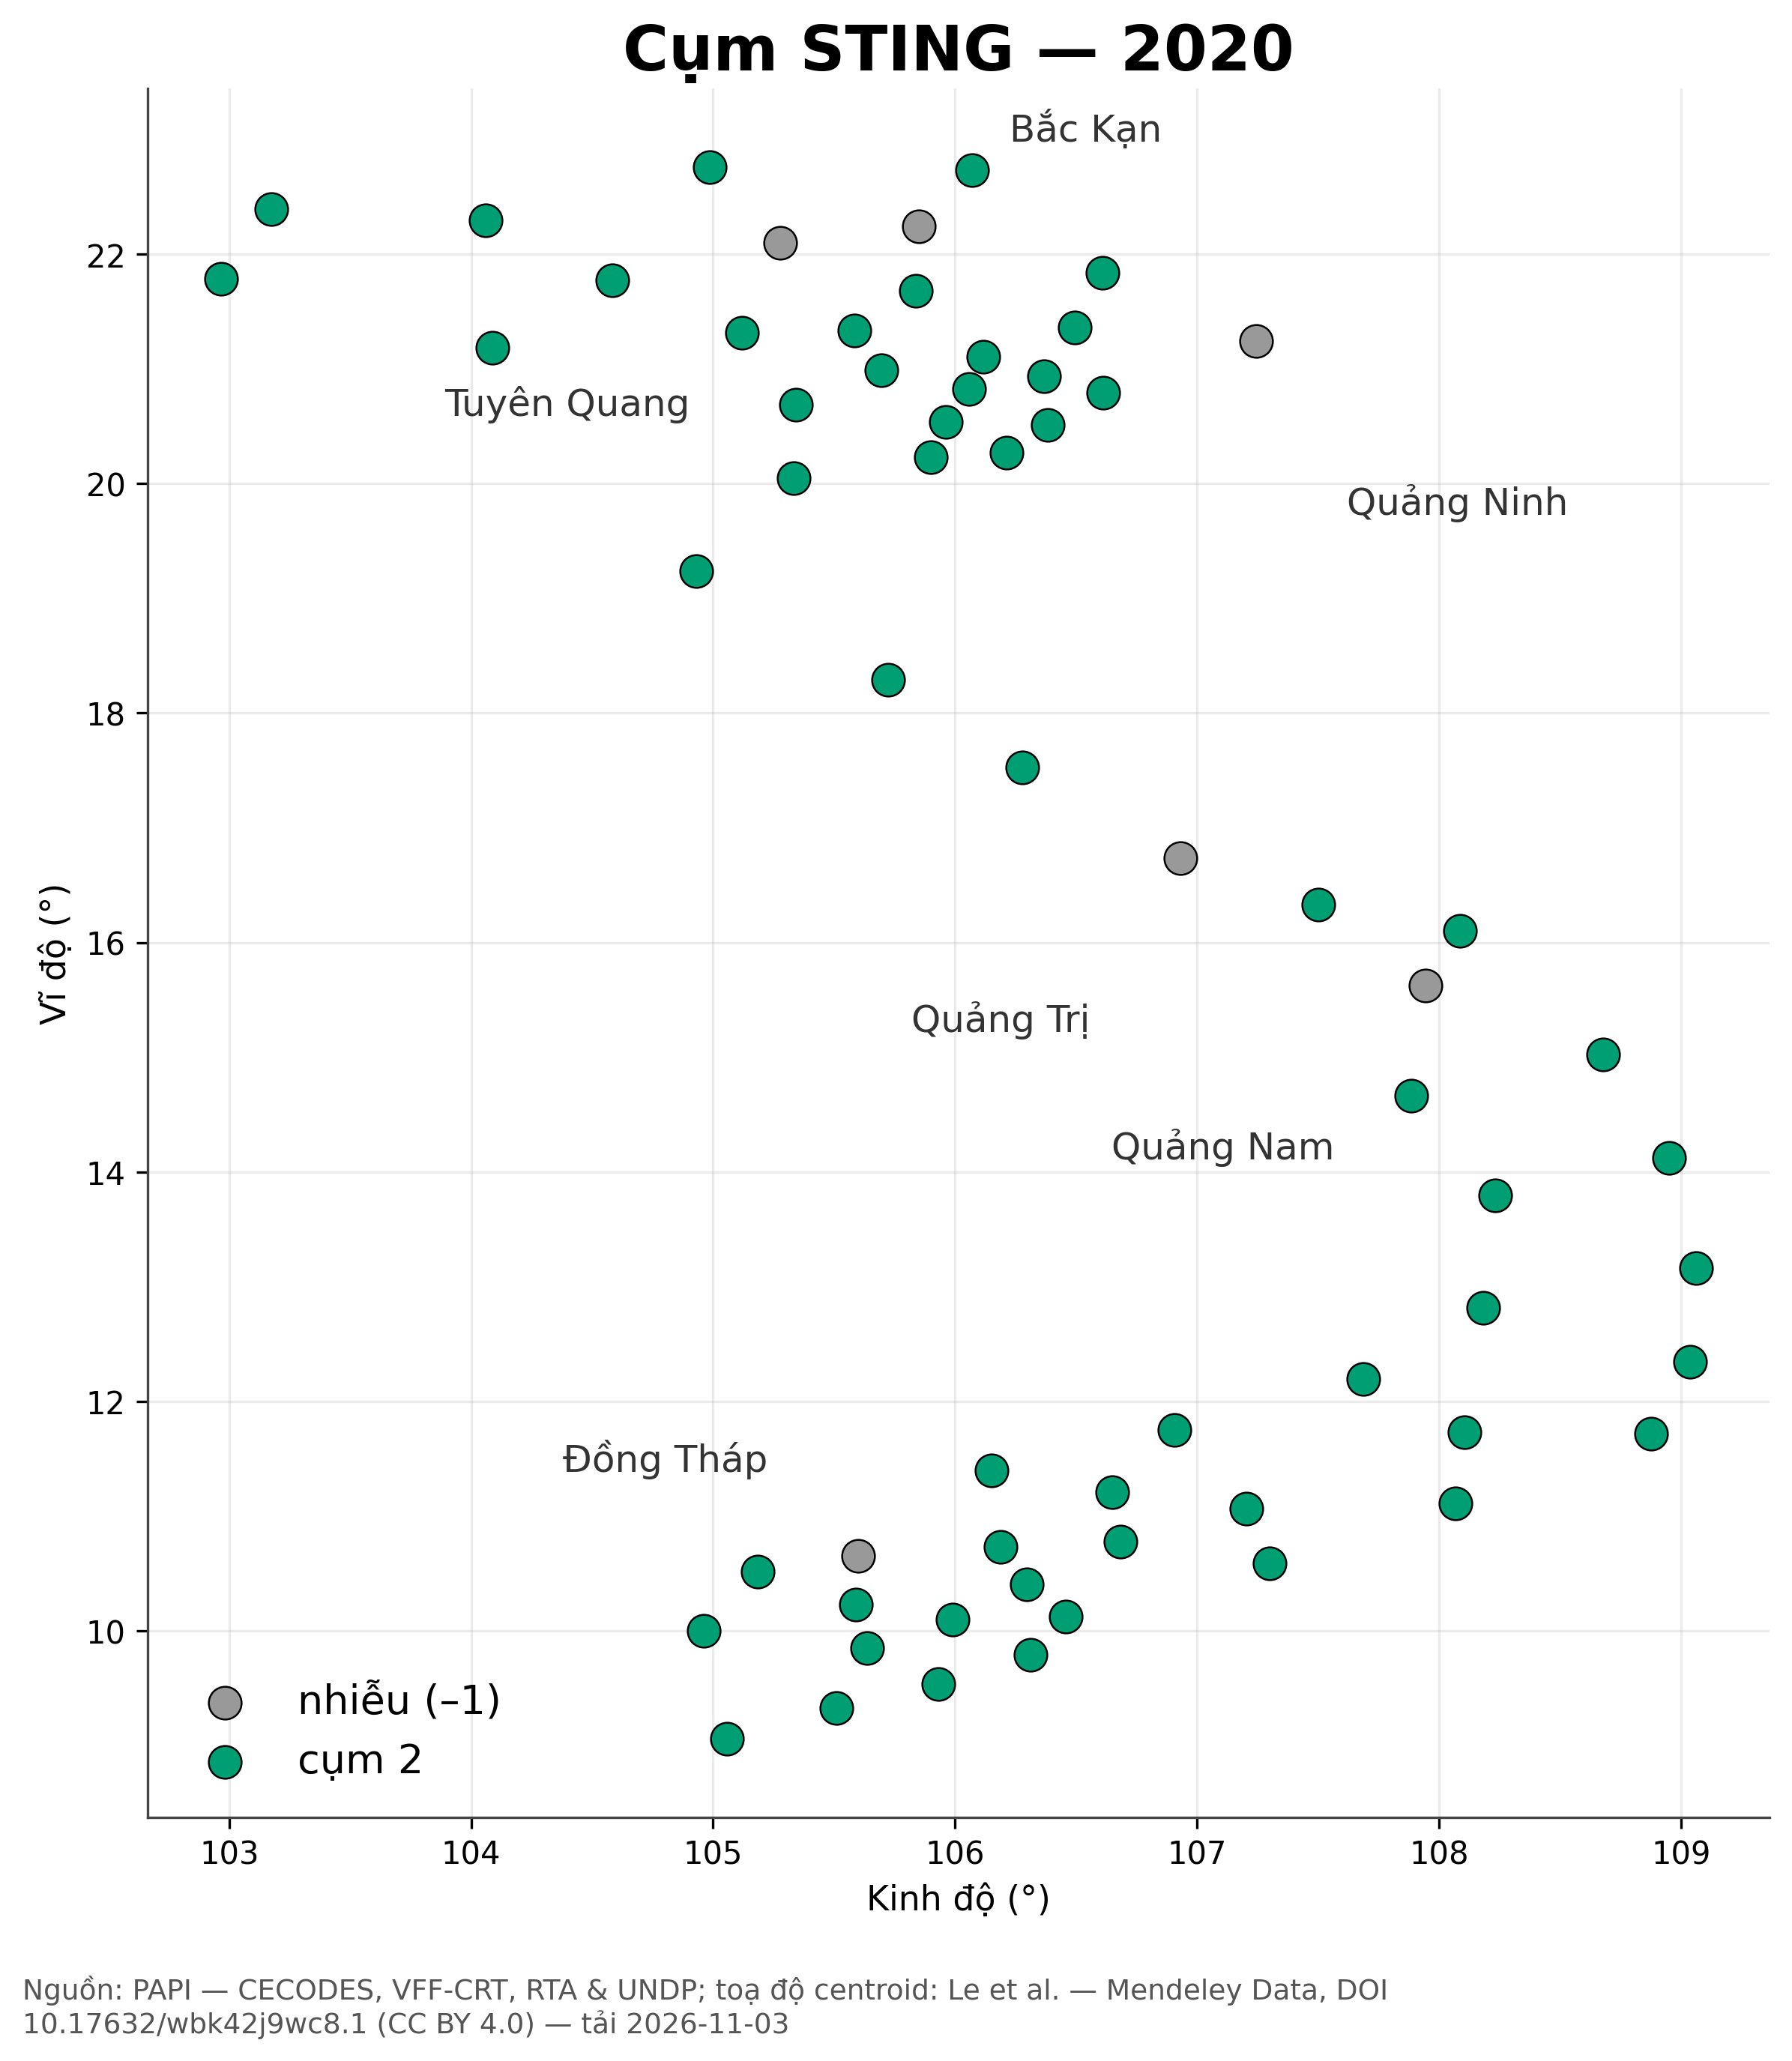

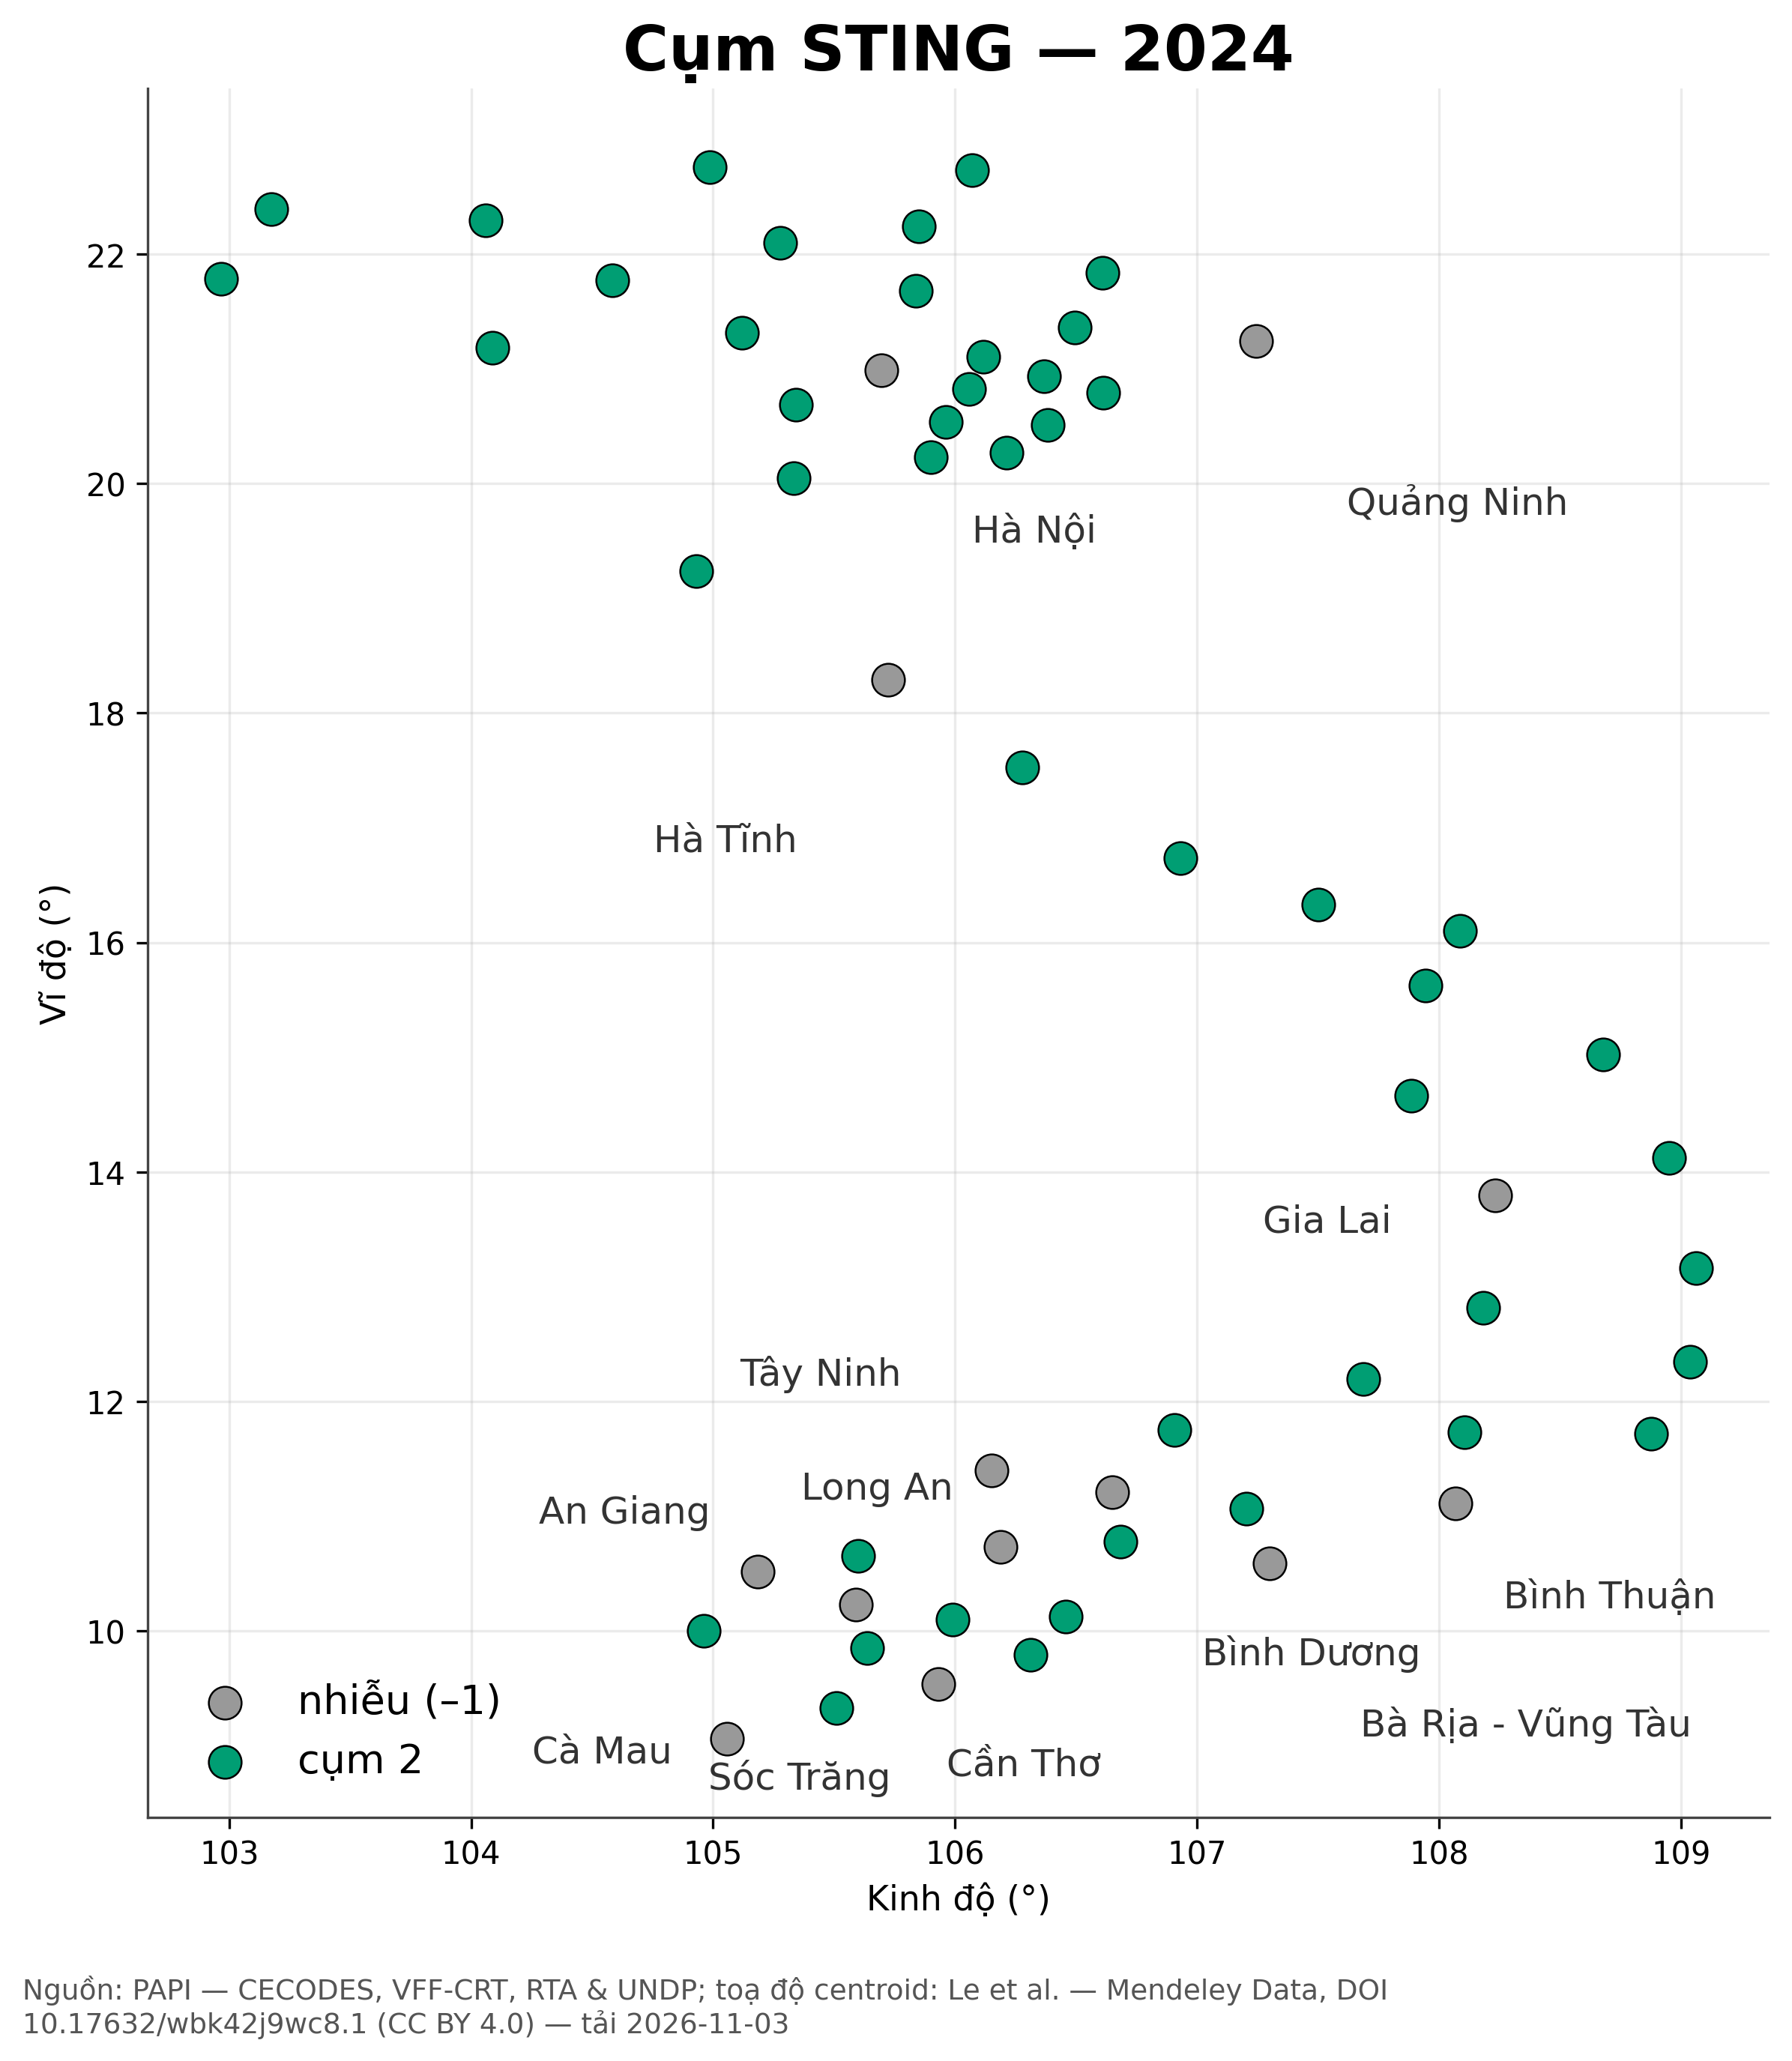

In [16]:
for year in (2020, 2024):
    display(Image(filename=str(ROOT / f"results/figs/map_{year}.png")))

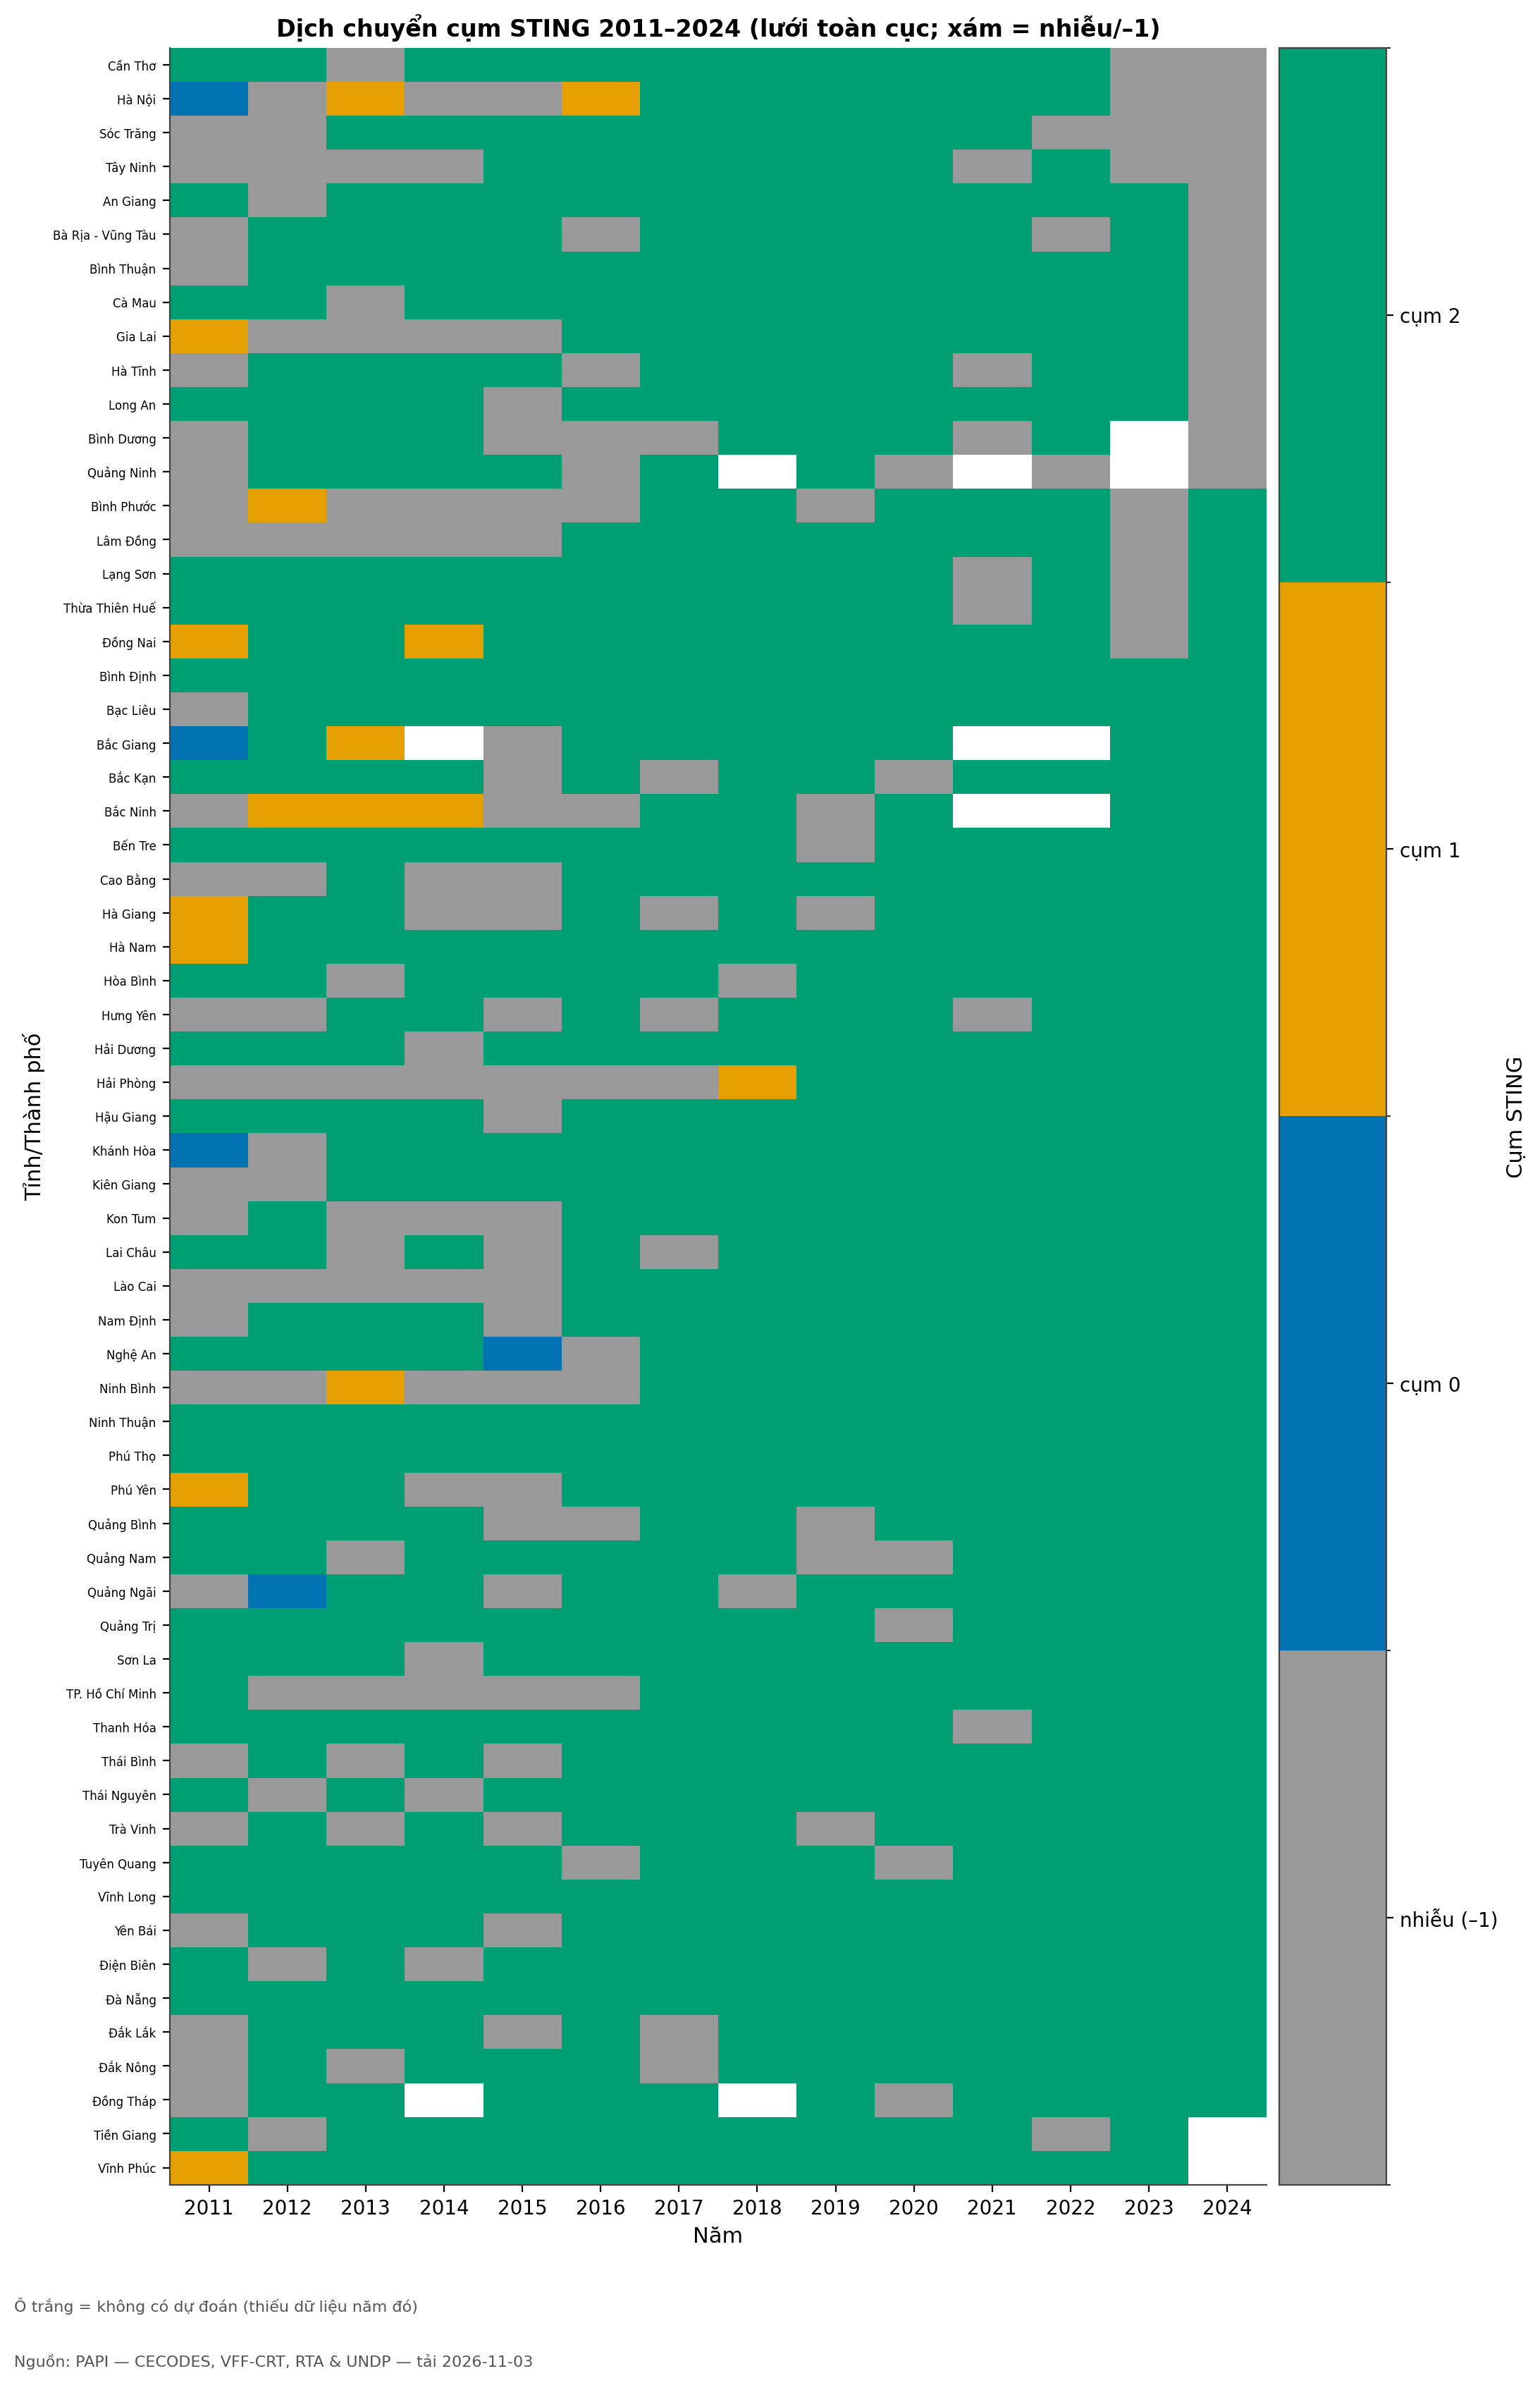

In [17]:
display(Image(filename=str(ROOT / "results/figs/evolution.png")))

**Mục đích của hình phân bổ quan sát 2024.** Đặt hai điểm PAPI đã quan
sát lên lưới đến 2023 để xem độ phủ của vùng dày và nhận diện những trường
hợp nằm ở ngoài vùng. Cùng lưới còn giúp theo dõi tỉnh đổi trạng thái giữa
hai năm. Phần dự báo dùng nhãn suy ra từ điểm quan sát làm mốc đối chiếu
với nhãn suy ra từ điểm do mô hình sinh.

Hai tỉnh thiếu chỉ tiêu được loại khỏi phép gán. Cả 13 tỉnh mang nhãn −1
đều đủ điểm và nằm trong ô có dưới 5 quan sát tham chiếu (không có tỉnh nào
rơi ngoài biên lưới hay có `|z| > 3`; `max |z| = 2,1299`). Nhóm giữ các điểm
này trong mẫu để báo đúng độ phủ 48/61 tỉnh và theo dõi cả các trường hợp đạt
điểm rất cao ở rìa phải/trên (Hà Tĩnh, Bình Thuận, Sóc Trăng, Bà Rịa - Vũng Tàu,
Quảng Ninh, Tây Ninh) lẫn các tỉnh thấp hơn ở chỉ tiêu 6.1 (Hà Nội, Cần Thơ).
Quảng Ninh và Bình Dương thiếu điểm năm 2023 nên sau khi ghép hai năm, bảng còn
59 tỉnh, gồm 48 trong vùng dày và 11 ngoài vùng dày.

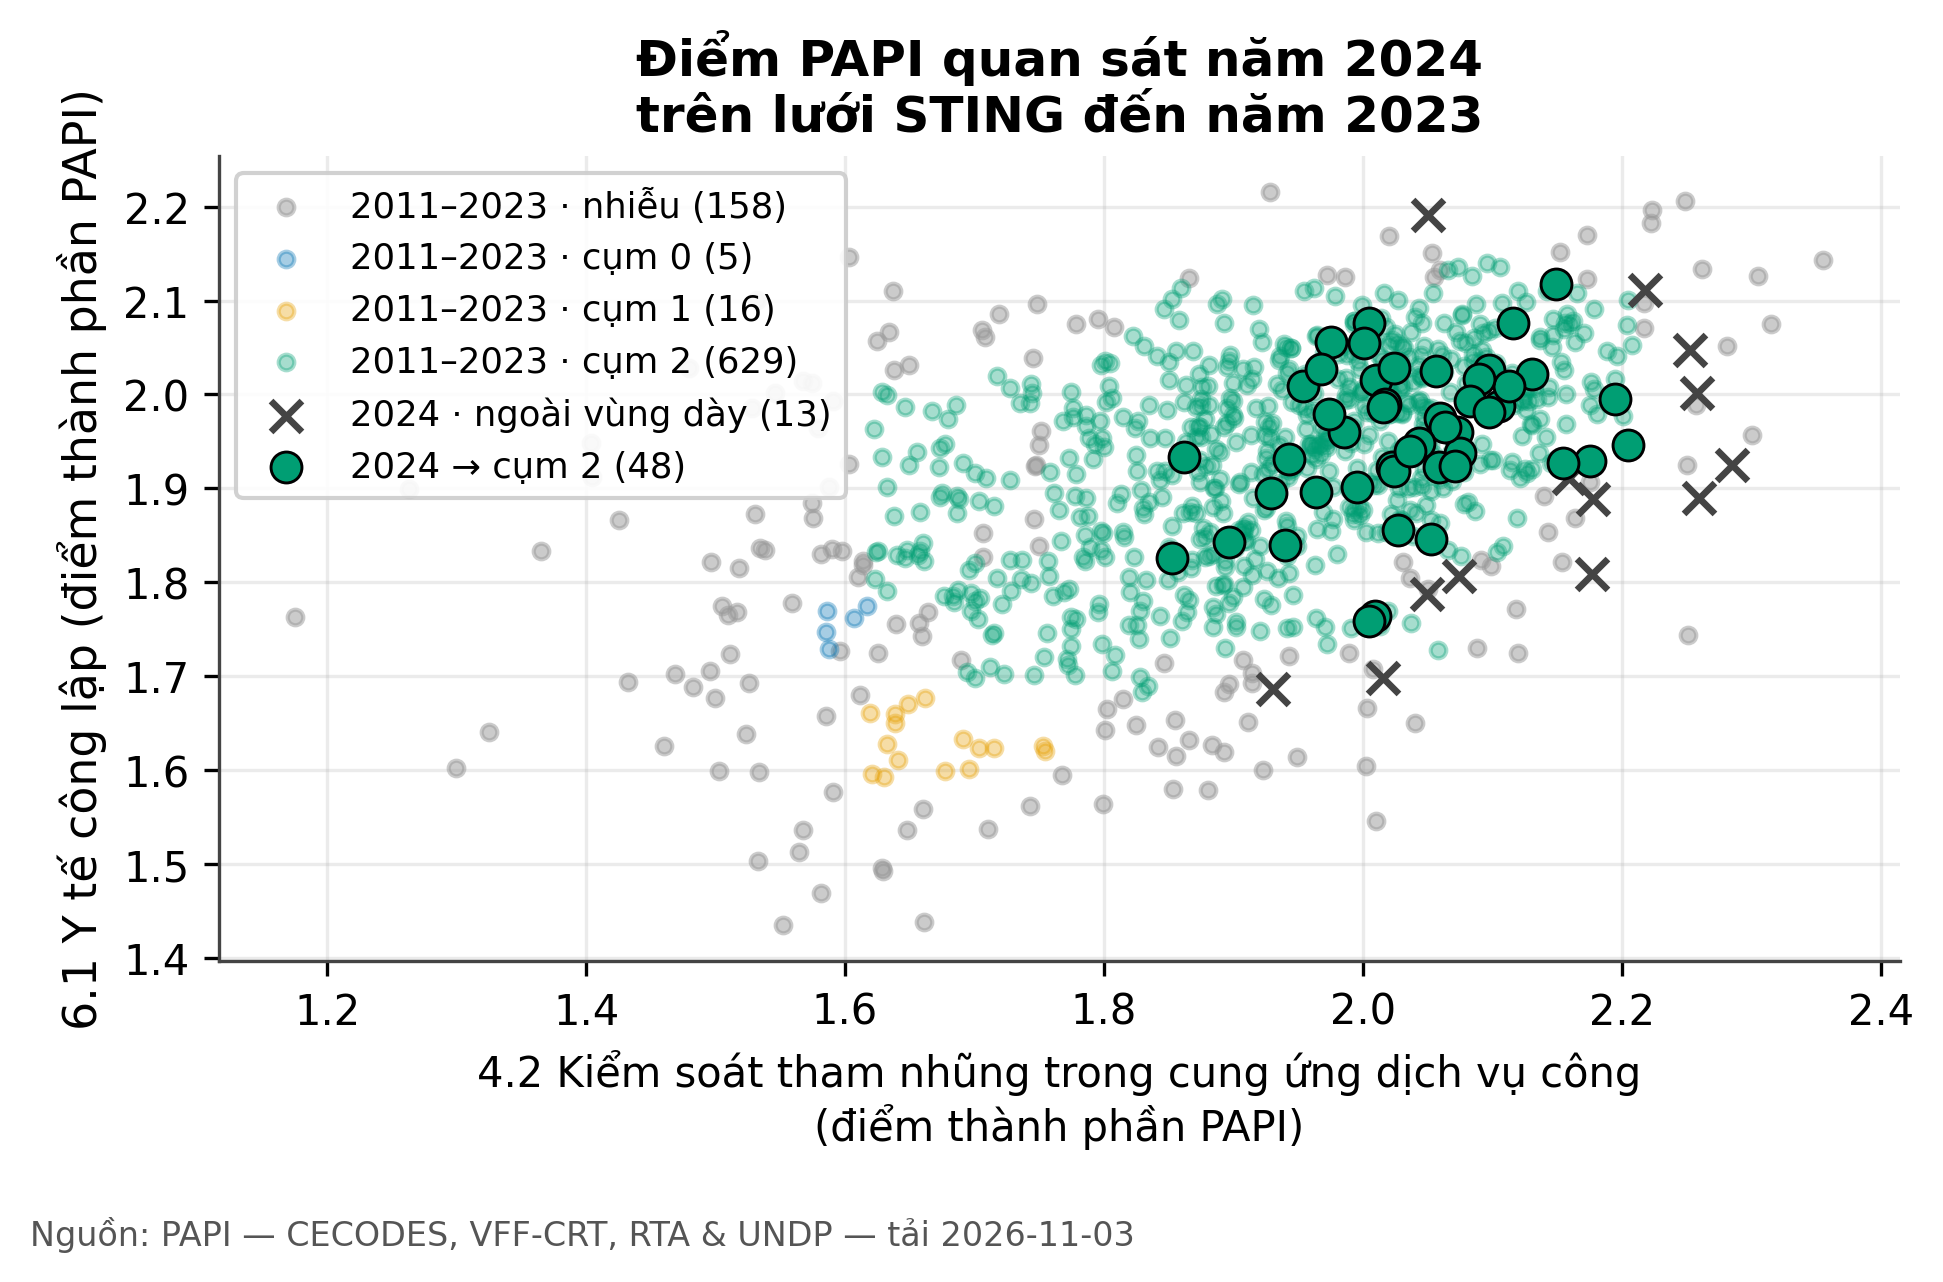

,Số tỉnh
Kết quả gán,
Thuộc cụm,48
Ô thưa,13
Thiếu chỉ tiêu,2


Cả 13/13 tỉnh ô thưa năm 2024 đều có |z| ≤ 3 trên lưới tham chiếu (|z| lớn nhất = 2.1299).


,Tỉnh/thành phố,Điểm 4.2,Điểm 6.1,|z| lớn nhất,Ô lưới,Số điểm tham chiếu,Lý do
0,Hà Nội,1.9308,1.6863,1.5792,"(10, 5)",3,Ô thưa
1,Quảng Ninh,2.2598,1.8891,1.9907,"(14, 9)",0,Ô thưa
2,Vĩnh Phúc,NaN,NaN,NaN,<NA>,<NA>,Thiếu chỉ tiêu
3,Hà Tĩnh,2.0502,2.1914,2.0571,"(11, 15)",1,Ô thưa
4,Bình Thuận,2.2182,2.1117,1.7625,"(14, 13)",2,Ô thưa
5,Gia Lai,2.0496,1.7875,0.8504,"(11, 7)",3,Ô thưa
6,Tây Ninh,2.2852,1.9245,2.1299,"(15, 10)",1,Ô thưa
7,Bình Dương,2.1768,1.8083,1.5351,"(13, 7)",1,Ô thưa
8,Bà Rịa - Vũng Tàu,2.2581,2.0017,1.9811,"(14, 11)",1,Ô thưa
9,Long An,2.0740,1.8069,0.9715,"(12, 7)",2,Ô thưa


Bảng 63 tỉnh kèm ô, số điểm tham chiếu và lý do gán nằm trong results/papi_observed_grid_2024.csv.
Lạng Sơn 2023: ngoài vùng dày trên cùng lưới đến năm 2023.
Lạng Sơn 2024: cụm 2 trên cùng lưới đến năm 2023.


In [18]:
from scripts.common.papi_pred_common import GRID_ASSIGNMENT_LABELS, describe_grid_assignment

display(Image(filename=str(ROOT / "results/figs/predict_2024.png")))
observed_grid = describe_grid_assignment(panel.loc[panel.year.eq(2024)], features, scaler, sting)
status_counts = observed_grid.grid_status.value_counts().rename(index=GRID_ASSIGNMENT_LABELS)
display(status_counts.rename("Số tỉnh").rename_axis("Kết quả gán").to_frame())
review_2024 = observed_grid.loc[observed_grid.grid_status.ne("in_cluster")].copy()
valid_2024 = review_2024[features].notna().all(axis=1)
review_2024["max_abs_z"] = np.nan
review_2024.loc[valid_2024, "max_abs_z"] = np.abs(
    scaler.transform(review_2024.loc[valid_2024, features])
).max(axis=1)
sparse_2024 = review_2024.loc[review_2024.grid_status.eq("sparse_cell")]
assert (sparse_2024["max_abs_z"] <= 3).all()
print(f"Cả {len(sparse_2024)}/{len(sparse_2024)} tỉnh ô thưa năm 2024 đều có |z| ≤ 3 "
      f"trên lưới tham chiếu (|z| lớn nhất = {sparse_2024['max_abs_z'].max():.4f}).")
review_2024["grid_status"] = review_2024.grid_status.map(GRID_ASSIGNMENT_LABELS)
display(review_2024[["province_vi", *features, "max_abs_z", "grid_cell", "reference_count", "grid_status"]].rename(columns={
    "province_vi": "Tỉnh/thành phố", "sd_4_2": "Điểm 4.2", "sd_6_1": "Điểm 6.1",
    "max_abs_z": "|z| lớn nhất", "grid_cell": "Ô lưới",
    "reference_count": "Số điểm tham chiếu", "grid_status": "Lý do",
}).round(4).reset_index(drop=True))
print("Bảng 63 tỉnh kèm ô, số điểm tham chiếu và lý do gán nằm trong results/papi_observed_grid_2024.csv.")
lang_son_code = panel.loc[panel.province_vi.eq("Lạng Sơn"), "province_code"].iat[0]
lang_son = paired.loc[lang_son_code]
for year, label in lang_son.items():
    region = "ngoài vùng dày" if label == -1 else f"cụm {label}"
    print(f"Lạng Sơn {year}: {region} trên cùng lưới đến năm 2023.")

### 4.1 Dự báo hai chỉ tiêu năm 2024 từ dữ liệu đến năm 2023

Từ tám chỉ tiêu ở năm t, nhóm dự báo **4.2 Kiểm soát tham nhũng trong cung
ứng dịch vụ công** và **6.1 Y tế công lập** ở năm t+1. Ghép cặp theo mã tỉnh
và hai năm liên tiếp. Bốn ứng viên gồm giữ điểm năm trước, Ridge, Random
Forest và trung bình 50/50 của hai mô hình. Chọn riêng cho từng chỉ tiêu
bằng MAE trung bình của sáu lượt kiểm định theo thời gian. Mỗi lượt chỉ
dùng cặp huấn luyện có năm đích đến mốc xuất phát của lượt đó.

Với mốc cuối 2023, ô dưới tạo hai điểm dự báo cho 2024 từ lịch sử. Scaler
và lưới STING cũng được dựng từ lịch sử. Điểm PAPI 2024 sẽ được dùng ở ô
đối chiếu kế tiếp. Đây là đánh giá hồi cứu trên một năm đã có số liệu.

In [19]:
from scripts.common.papi_forecast import (
    FEATURES, MODEL_NAMES, ORIGIN_YEAR, TARGETS, forecast_from_history, scenario_auc, score_forecast,
)

history = panel.loc[panel.year <= ORIGIN_YEAR].copy()
assert tuple(cfg["features"]) == TARGETS
run = forecast_from_history(history, cfg["sting"])
folds = run.validation[["origin_year", "target_year", "last_train_target_year",
                        "n_train", "n_validation"]].drop_duplicates()
assert folds.last_train_target_year.le(folds.origin_year).all()
assert folds.target_year.le(ORIGIN_YEAR).all()
print(f"Huấn luyện cuối: {run.train_pairs} cặp. Dự báo: {len(run.predictions)} tỉnh đủ tám đầu vào.")
print("Tám đầu vào:", ", ".join(FEATURES))
display(folds.rename(columns={
    "origin_year": "Mốc xuất phát", "target_year": "Năm đích kiểm định",
    "last_train_target_year": "Năm đích huấn luyện cuối", "n_train": "Cặp huấn luyện",
    "n_validation": "Cặp kiểm định",
}))
avg = run.validation.pivot_table(index="target", columns="method", values="mae")
display(avg.rename(columns=MODEL_NAMES).round(4))
for target, method in run.selection.items():
    print(f"{target}: {MODEL_NAMES[method]} theo MAE trung bình qua sáu lượt kiểm định.")

Huấn luyện cuối: 738 cặp. Dự báo: 61 tỉnh đủ tám đầu vào.
Tám đầu vào: sd_1_3, sd_1_4, sd_4_1, sd_4_2, sd_4_3, sd_4_4, sd_6_1, sd_6_3


,Mốc xuất phát,Năm đích kiểm định,Năm đích huấn luyện cuối,Cặp huấn luyện,Cặp kiểm định
0,2017,2018,2017,374,61
8,2018,2019,2018,435,61
16,2019,2020,2019,496,63
24,2020,2021,2020,559,60
32,2021,2022,2021,619,60
40,2022,2023,2022,679,59


method,Trung bình Ridge và Random Forest,Giữ điểm năm trước,Random Forest,Ridge
target,,,,
sd_4_2,0.0988,0.1077,0.1008,0.0984
sd_6_1,0.0672,0.0711,0.0695,0.0664


sd_4_2: Ridge theo MAE trung bình qua sáu lượt kiểm định.
sd_6_1: Ridge theo MAE trung bình qua sáu lượt kiểm định.


### 4.2 Đo sai số dự báo trên các tỉnh đối chiếu được

Ghép điểm PAPI 2024 theo mã tỉnh. Cùng một nhóm tỉnh có đủ hai điểm thực
tế được dùng để tính MAE, RMSE và độ lệch trung bình cho cả mô hình lẫn
mốc giữ nguyên. MAE là trung bình độ lệch tuyệt đối. RMSE nhạy hơn với
sai số lớn. Độ lệch âm cho biết dự báo thấp hơn quan sát về trung bình.

Có 61 tỉnh đủ tám đầu vào năm 2023 để tạo dự báo và 61 tỉnh đủ hai điểm
quan sát năm 2024 để gán lên lưới. Hai tiêu chí chọn được 59 tỉnh chung.
Với chỉ tiêu 4.2, Ridge giảm MAE. So với giữ điểm 2023, RMSE tăng từ
0,0953 lên 0,0972 và độ lệch trung bình từ −0,0245 xuống −0,0581.

Có 61 dự báo, đối chiếu được 59 tỉnh đủ hai điểm quan sát.
Có điểm thực tế 2024 nhưng thiếu đầu vào 2023: Quảng Ninh, Bình Dương.
Ngoài vùng dày: 13/61 tỉnh quan sát, 11/59 tỉnh đối chiếu dự báo.


,Chỉ tiêu,Cách dự báo,Số tỉnh,MAE,RMSE,Độ lệch trung bình
0,sd_4_2,Mô hình đã chọn,59,0.0736,0.0972,-0.0581
1,sd_4_2,Giữ điểm 2023,59,0.0763,0.0953,-0.0245
2,sd_6_1,Mô hình đã chọn,59,0.0641,0.0770,-0.0308
3,sd_6_1,Giữ điểm 2023,59,0.0683,0.0875,-0.0333


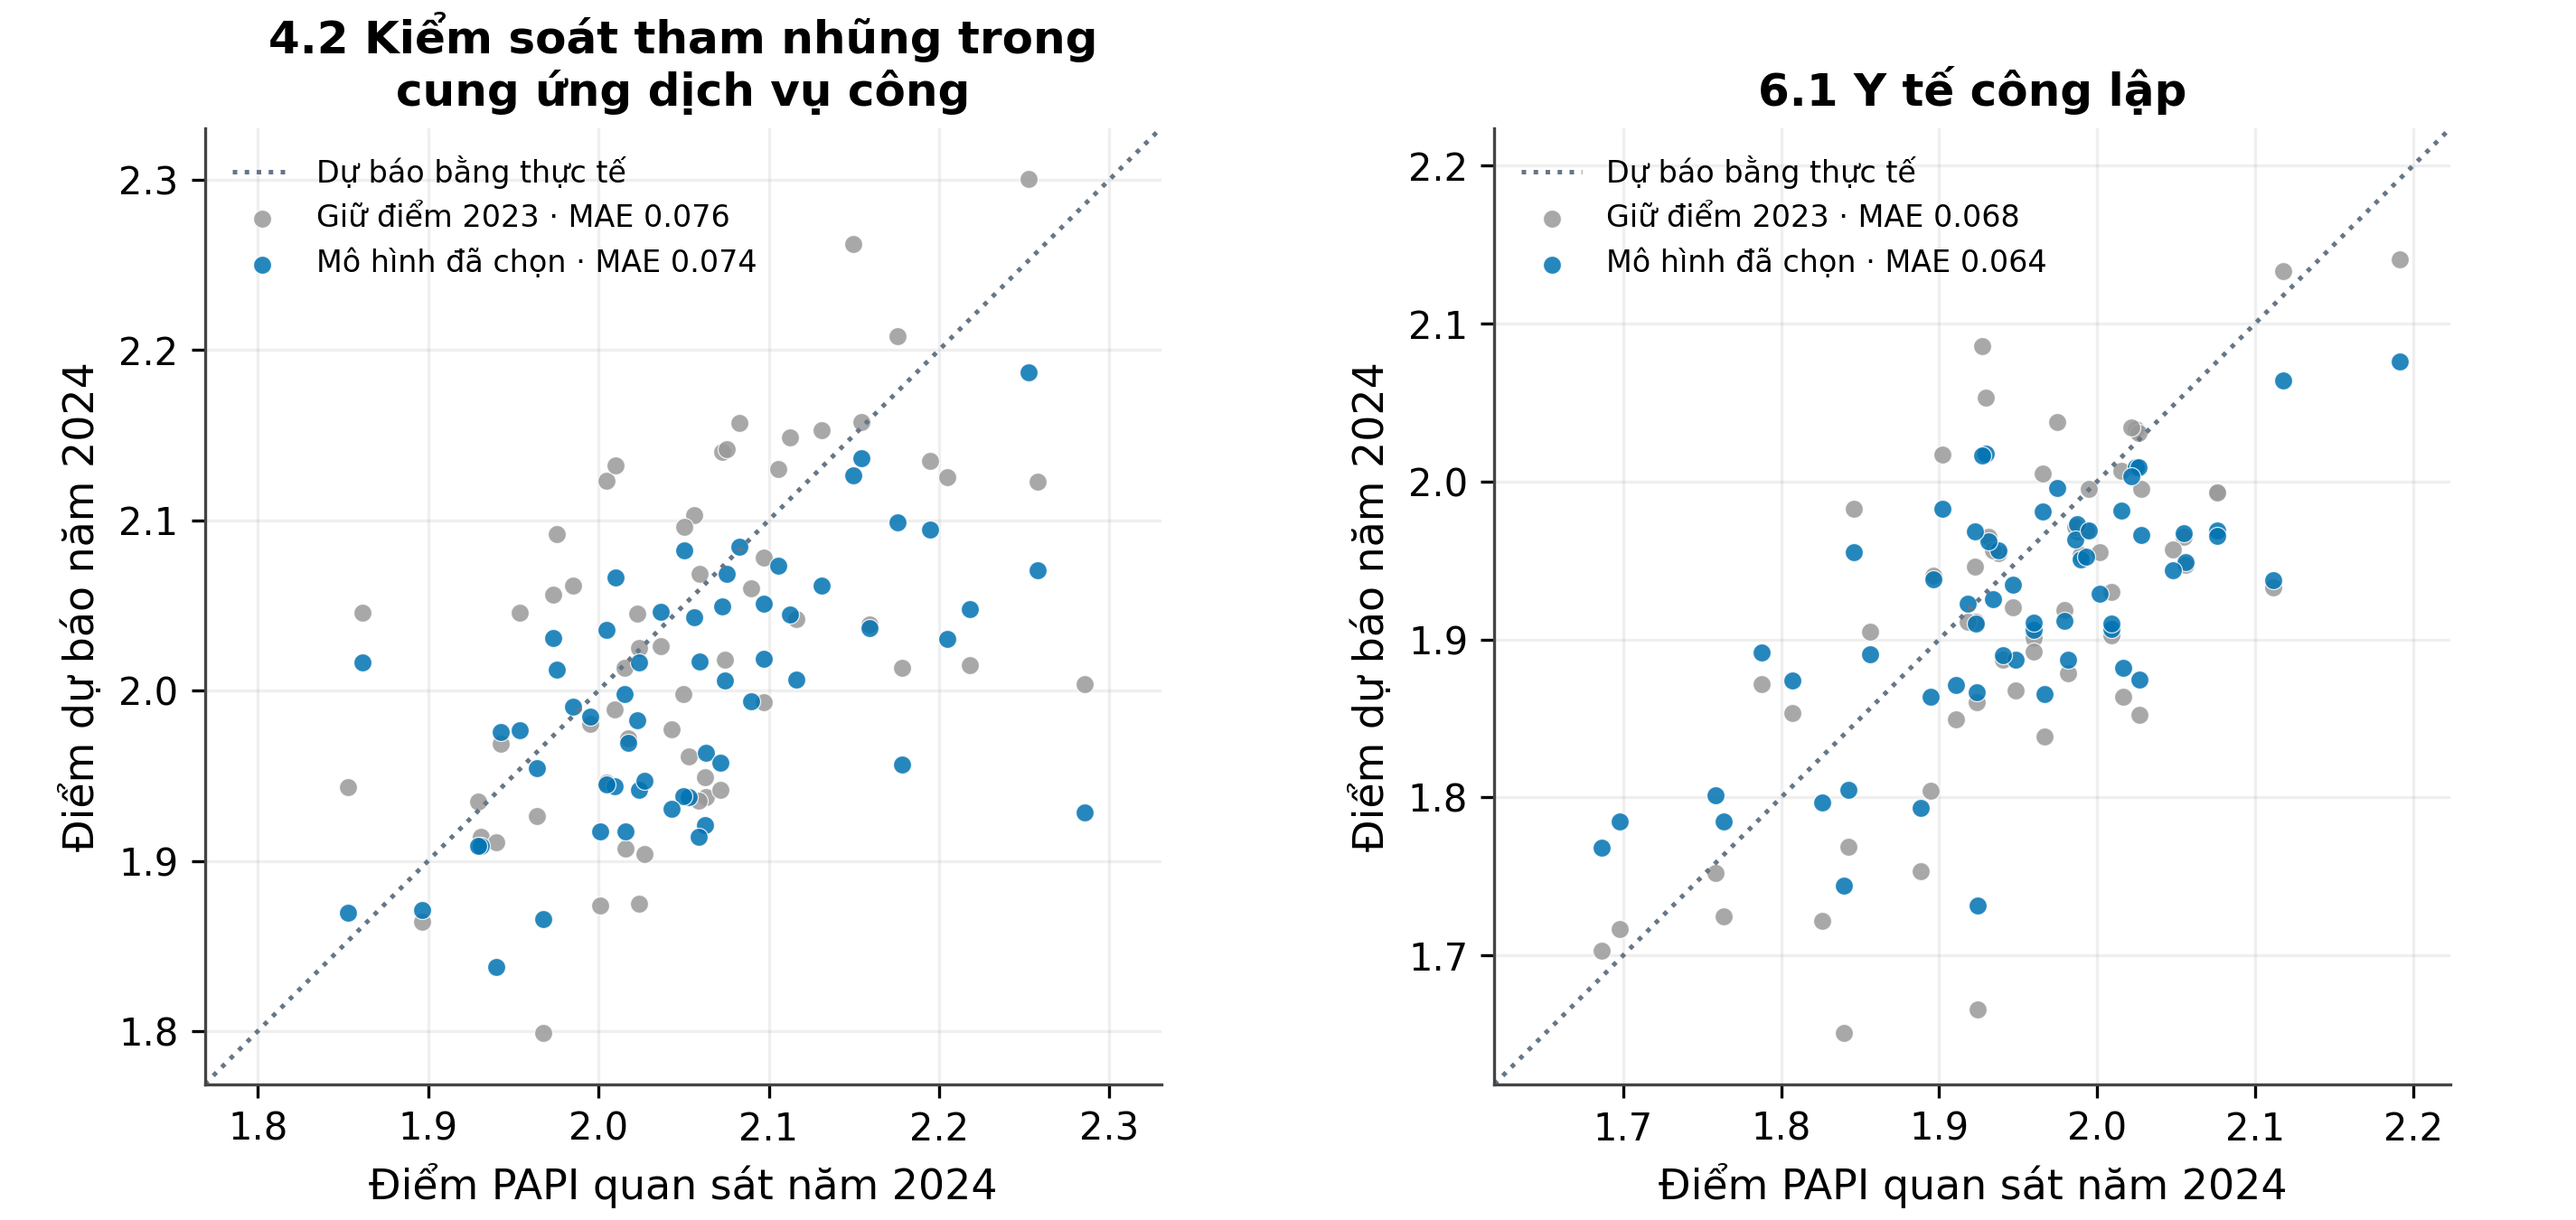

In [20]:
observed = panel.loc[panel.year == ORIGIN_YEAR + 1].copy()
scored, errors, zones = score_forecast(run, observed)
archive_table = pd.read_csv(ROOT / "results/papi_forecast_provinces_2024.csv")
pd.testing.assert_frame_equal(scored.astype({"actual_cluster": "float64"}), archive_table,
                              check_dtype=False, check_exact=False, atol=1e-9, rtol=1e-9)
n_matched = int(scored.actual_cluster.notna().sum())
print(f"Có {len(scored)} dự báo, đối chiếu được {n_matched} tỉnh đủ hai điểm quan sát.")
actual_eligible = observed_grid.loc[observed_grid.cluster.notna()]
matched_codes = scored.loc[scored.actual_cluster.notna(), "province_code"]
omitted = actual_eligible.loc[~actual_eligible.province_code.isin(matched_codes), "province_vi"]
print(f"Có điểm thực tế 2024 nhưng thiếu đầu vào 2023: {', '.join(omitted)}.")
print(f"Ngoài vùng dày: {actual_eligible.cluster.eq(-1).sum()}/{len(actual_eligible)} tỉnh quan sát, "
      f"{scored.actual_cluster.eq(-1).sum()}/{n_matched} tỉnh đối chiếu dự báo.")
display(errors.rename(columns={
    "target": "Chỉ tiêu", "method": "Cách dự báo", "n": "Số tỉnh", "mae": "MAE", "rmse": "RMSE",
    "bias": "Độ lệch trung bình",
}).replace({"forecast": "Mô hình đã chọn", "carry": "Giữ điểm 2023"}).round(4))
display(Image(filename=str(ROOT / "results/figs/papi_forecast_values.png")))

### 4.3 Đọc vùng STING khi phần lớn điểm nằm trong cụm lớn

Chiếu các điểm dự báo, điểm giữ nguyên và điểm quan sát vào **cùng lưới
đến 2023**. Thêm đối chứng luôn chọn cụm phổ biến nhất trong lịch sử.
Tỷ lệ trùng nhãn dùng nhãn suy ra từ lưới, còn tỷ lệ phát hiện ngoài vùng
dày tính riêng trên số tỉnh có điểm quan sát ngoài vùng dày.

Điểm dự báo đưa cả 59 tỉnh vào cụm lớn và nhận ra 0/11 tỉnh ngoài vùng.
Mức trùng nhãn 48/59 và độ đúng cân bằng 0,50 bằng mốc luôn chọn cụm lớn.

Nhóm giữ nguyên từng cặp sai số ngoài lượt kiểm định của hai chỉ tiêu,
cộng chúng vào hai điểm dự báo rồi chiếu từng kịch bản lên lưới. Tỷ lệ
kịch bản ngoài vùng dày là thước đo độ nhạy theo sai số lịch sử. AUC đánh
giá việc xếp hạng các tỉnh khi đối chiếu năm 2024. Đây là kiểm tra thăm dò
trên một năm, với sai số gộp từ các tỉnh và năm trước.

,Cách gán vùng,Số tỉnh,Nhận ra ngoài vùng,Bỏ sót,Gán ngoài nhầm,Trùng nhãn lưới,Tỷ lệ nhận ra ngoài vùng,Độ đúng cân bằng hai vùng
0,Điểm dự báo,59,0,11,0,0.8136,0.0000,0.5000
1,Giữ điểm 2023,59,4,7,5,0.7966,0.3636,0.6297
2,Luôn chọn cụm lớn,59,0,11,0,0.8136,0.0000,0.5000


Dự báo điểm bỏ sót 11 tỉnh ngoài vùng dày.
364 cặp sai số lịch sử mỗi tỉnh. AUC xếp hạng ngoài vùng = 0.8163.


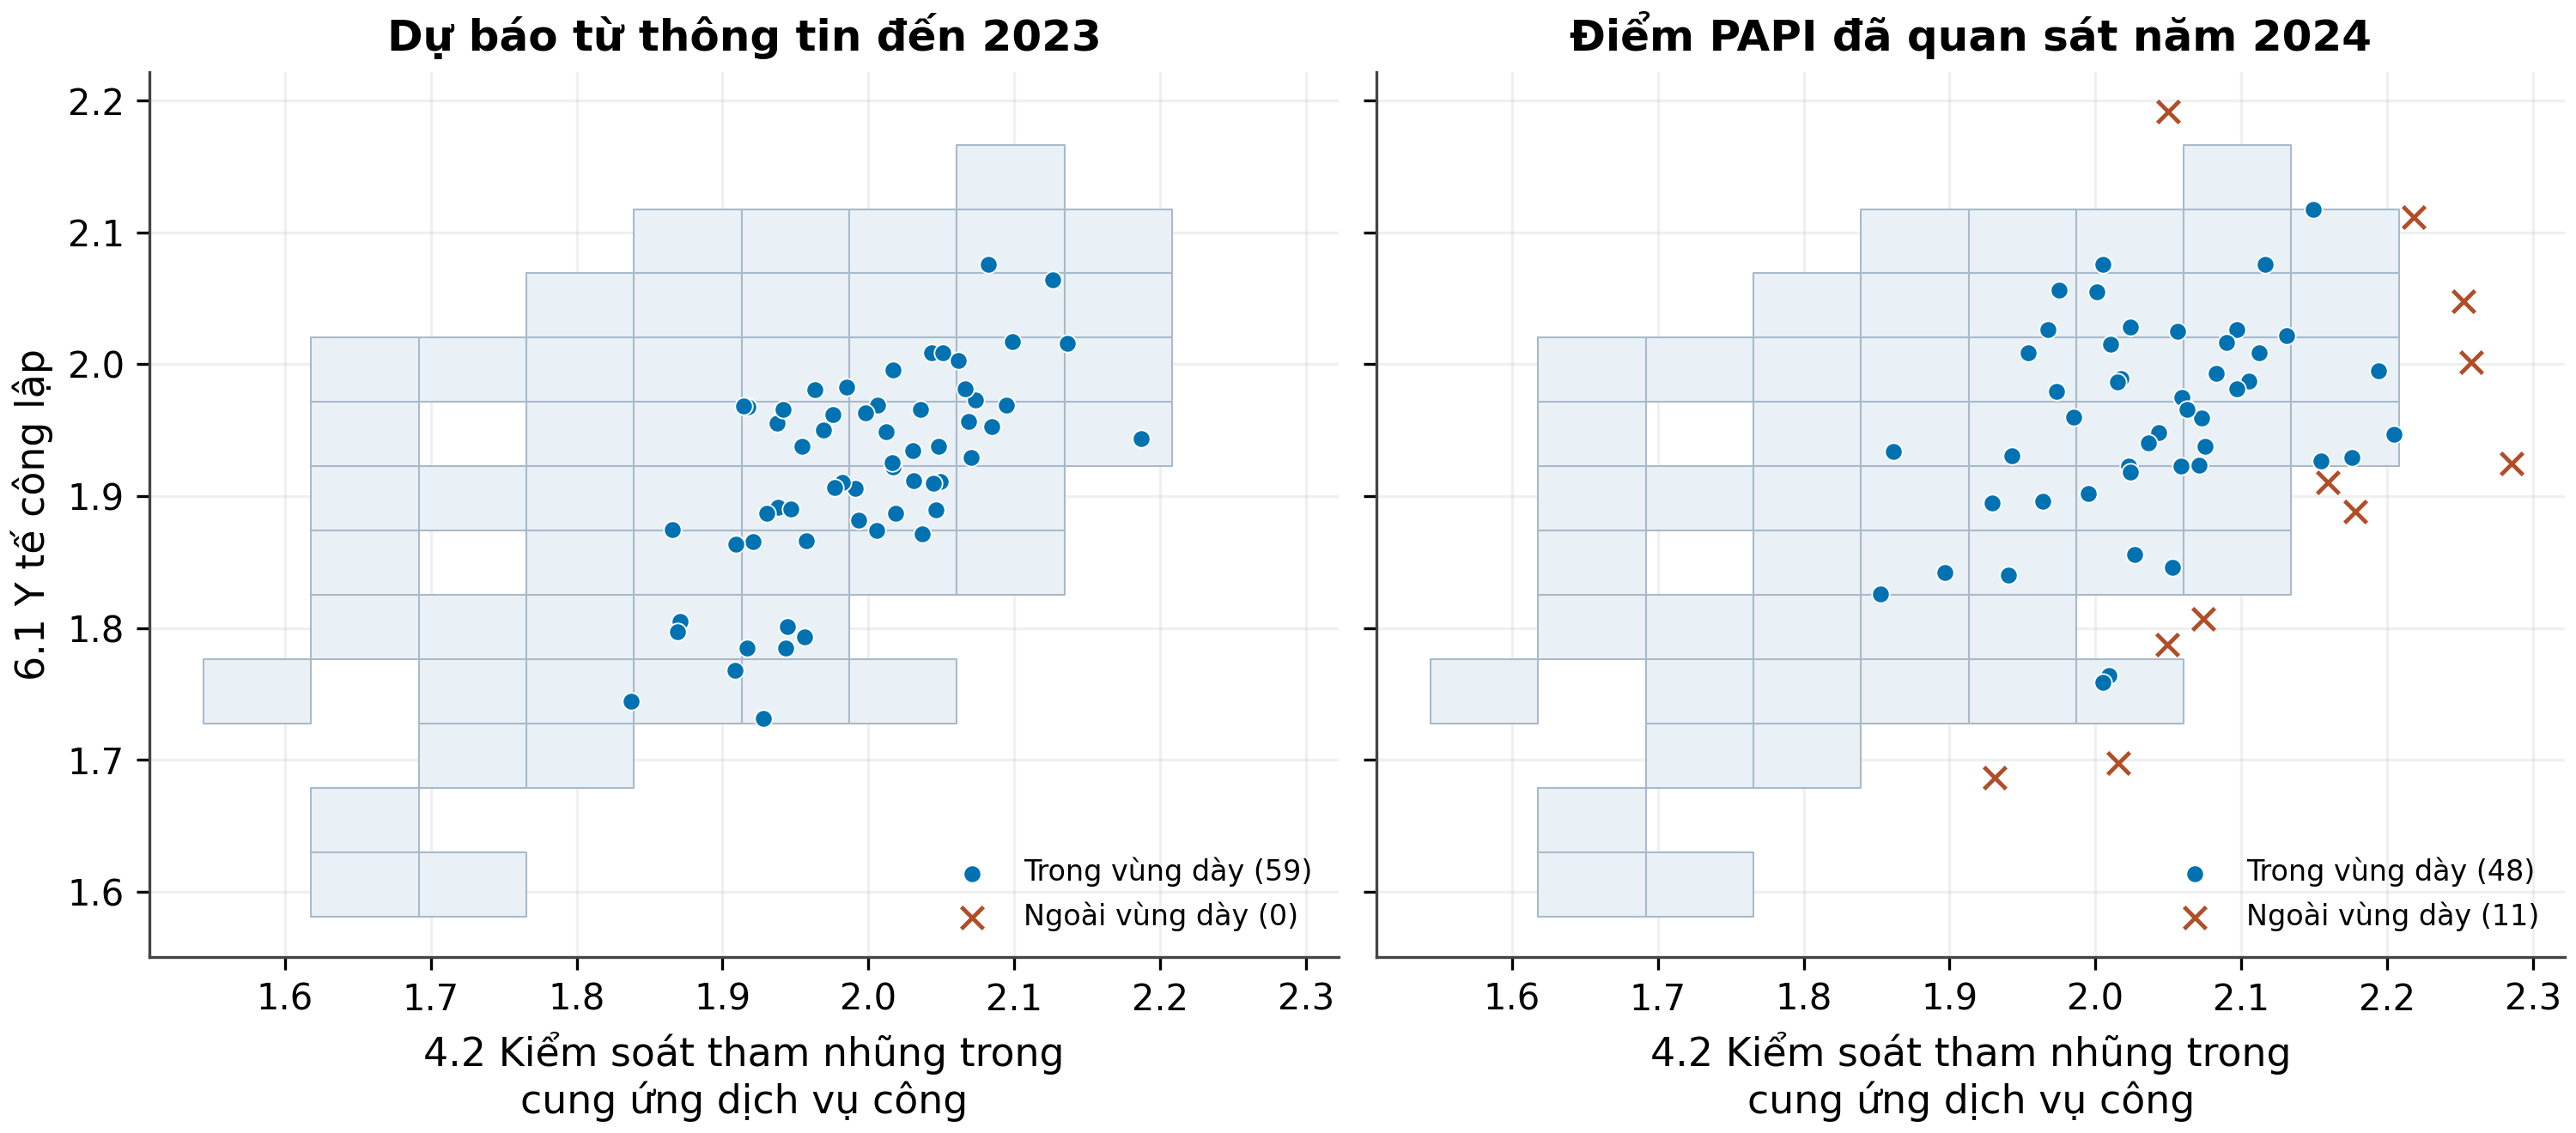

Lạng Sơn, sd_4_2: điểm 2023 = 2.1400, dự báo = 2.0494, quan sát 2024 = 2.0727.
Lạng Sơn, sd_6_1: điểm 2023 = 1.8922, dự báo = 1.9109, quan sát 2024 = 1.9596.
Kết quả từng tỉnh nằm trong results/papi_forecast_provinces_2024.csv.


In [21]:
zone_table = zones[["method", "n", "out_correct", "missed_out", "false_out",
                    "exact_label_agreement", "out_recall", "balanced_zone_accuracy"]]
display(zone_table.rename(columns={
    "method": "Cách gán vùng", "n": "Số tỉnh", "out_correct": "Nhận ra ngoài vùng",
    "missed_out": "Bỏ sót", "false_out": "Gán ngoài nhầm", "exact_label_agreement": "Trùng nhãn lưới",
    "out_recall": "Tỷ lệ nhận ra ngoài vùng", "balanced_zone_accuracy": "Độ đúng cân bằng hai vùng",
}).replace({"forecast": "Điểm dự báo", "carry": "Giữ điểm 2023", "majority": "Luôn chọn cụm lớn"}).round(4))
false_negatives = int(zones.loc[zones.method.eq("forecast"), "missed_out"].item())
print(f"Dự báo điểm bỏ sót {false_negatives} tỉnh ngoài vùng dày.")
print(f"{run.scenario_count} cặp sai số lịch sử mỗi tỉnh. AUC xếp hạng ngoài vùng = {scenario_auc(scored):.4f}.")
display(Image(filename=str(ROOT / "results/figs/papi_forecast_grid.png")))
probe = scored.loc[scored.province_vi.eq("Lạng Sơn")].iloc[0]
for target in TARGETS:
    print(f"Lạng Sơn, {target}: điểm 2023 = {probe[f'carry_{target}']:.4f}, "
          f"dự báo = {probe[f'forecast_{target}']:.4f}, quan sát 2024 = {probe[f'actual_{target}']:.4f}.")
print("Kết quả từng tỉnh nằm trong results/papi_forecast_provinces_2024.csv.")

## 5. Kết luận

- STING gom các ô dày liên thông. Trên PAPI 2011–2023, cụm lớn có 629 điểm,
  hai cụm nhỏ có 16 và 5 điểm, với 19,6% nhiễu.
- Các cấu hình lưới làm thay đổi số cụm và tỷ lệ nhiễu. Kết quả mô tả hai chỉ
  tiêu được chọn, trong phạm vi lưới và thời gian đã kiểm tra.
- Khi đọc silhouette, xem cùng tỉ lệ nhiễu. Các phương pháp có thể được đánh giá
  trên các tập điểm khác nhau.
- Dự báo điểm giảm MAE cho cả hai chỉ tiêu so với giữ nguyên năm 2023, trong
  khi RMSE của 4.2 tăng nhẹ. Khi chiếu dự báo điểm lên lưới, kết quả nghiêng
  về cụm lớn và bỏ sót các quan sát ngoài vùng dày. Sai số điểm và độ đúng
  theo vùng cần được đọc riêng.

**Nguồn:** Wang, Yang & Muntz (VLDB 1997), PAPI (CECODES/VFF-CRT/RTA/UNDP),
Le et al. (Mendeley DOI 10.17632/wbk42j9wc8.1) và Open Development Vietnam.

## Phụ lục A. Kiểm tra bổ sung trên nhiều chỉ tiêu

- Hai thành phần PCA giữ 63.2% phương sai và cho 1 cụm.
- Với 8 chiều giai đoạn 2018–2024, cấu hình gốc cho 3 cụm và 60.5% nhiễu.
- Khi chỉ đổi factor thành 3, tỷ lệ nhiễu là 91.9%. Khi đổi mức lưới,
  có 0 cụm. Khi giảm min_count còn 2, có 2 cụm và
  10.9% nhiễu, với silhouette -0.089.

In [22]:
rob = pd.read_csv(ROOT / "results/robustness.csv")
show_md(rob.to_markdown(index=False))

| branch                                                                   |   n |   explained_var_total |   k |   noise_ratio |   silhouette |        db |        ch |   ari_vs_2d | verdict         |
|:-------------------------------------------------------------------------|----:|----------------------:|----:|--------------:|-------------:|----------:|----------:|------------:|:----------------|
| PCA(2) d1–d6, within-year z, pooled                                      | 869 |                 0.632 |   1 |         0.062 |  nan         | nan       | nan       |       0.008 | không nhận diện |
| 8 chiều 2018–2024, within-year z, L=3 f=2 mc=10 lv=1 (gốc OFAT)          | 430 |               nan     |   3 |         0.605 |    0.297194  |   1.13107 |  83.8316  |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT f=3 (còn như gốc: L=3 mc=10 lv=1) | 430 |               nan     |   1 |         0.919 |  nan         | nan       | nan       |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT mc=2 (còn như gốc: L=3 f=2 lv=1)  | 430 |               nan     |   2 |         0.109 |   -0.0886574 |   1.49983 |   1.14207 |     nan     | có cấu trúc     |
| 8 chiều 2018–2024, within-year z, OFAT lv=2 (còn như gốc: L=3 f=2 mc=10) | 430 |               nan     |   0 |         1     |  nan         | nan       | nan       |     nan     | không nhận diện |

## Phụ lục B. Thí nghiệm học phần trên 6.1 và nhãn lưới

Thí nghiệm đơn chỉ tiêu này chọn mô hình theo R² và mẫu đủ 6.1. Mục 4 dùng
mẫu chung của cả hai chỉ tiêu và chọn theo MAE. Bài phân loại phụ đo mức
khớp với nhãn do STING sinh ở mốc 2023→2024.

In [23]:
sup = pd.read_csv(ROOT / "results/supervised_metrics.csv")
show_md(sup.to_markdown(index=False))

| task           | model                               | metric_cv                             |   value_cv |   holdout_mae |   holdout_rmse |   holdout_r2 |   holdout_acc |   holdout_macro_f1 |
|:---------------|:------------------------------------|:--------------------------------------|-----------:|--------------:|---------------:|-------------:|--------------:|-------------------:|
| regression     | carry-forward (giữ giá trị năm nay) | r2 (expanding origin 2017–2022)       |      0.145 |        0.0683 |         0.0875 |        0.198 |       nan     |            nan     |
| regression     | trung bình train                    | r2 (expanding origin 2017–2022)       |     -0.77  |        0.0814 |         0.1027 |       -0.105 |       nan     |            nan     |
| regression     | ridge                               | r2 (expanding origin 2017–2022)       |      0.265 |        0.064  |         0.0769 |        0.381 |       nan     |            nan     |
| regression     | random forest                       | r2 (expanding origin 2017–2022)       |      0.197 |        0.0616 |         0.0742 |        0.423 |       nan     |            nan     |
| classification | majority (lớp đa số)                | f1_macro (expanding origin 2017–2022) |      0.228 |      nan      |       nan      |      nan     |         0.186 |              0.157 |
| classification | logistic regression                 | f1_macro (expanding origin 2017–2022) |      0.434 |      nan      |       nan      |      nan     |         0.644 |              0.541 |
| classification | random forest                       | f1_macro (expanding origin 2017–2022) |      0.397 |      nan      |       nan      |      nan     |         0.678 |              0.6   |

In [24]:
import joblib
from sklearn.metrics import mean_absolute_error
from scripts.common.papi_pred_common import REGRESSION_FEATURES
from scripts.supervised.predict_supervised import build_regression_pairs, expanding_origin_folds

print("Tám chỉ tiêu dùng cho hồi quy:", ", ".join(REGRESSION_FEATURES))
regression_pairs = build_regression_pairs(panel)
training_origins = regression_pairs.loc[
    regression_pairs.year_t < 2023, "year_t"
].to_numpy()
print("Các lượt kiểm định theo thời gian dùng năm gốc trước 2023.")
folds = expanding_origin_folds(training_origins, first_validation_origin=2017)
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    print(
        f"Lượt {fold_number}: học đến năm gốc {training_origins[train_idx].max()}, "
        f"kiểm định tại năm gốc {training_origins[val_idx][0]}."
    )

regression_metrics = pd.read_csv(ROOT / "results/supervised_metrics.csv")
regression_models = regression_metrics[
    (regression_metrics.task == "regression")
    & ~regression_metrics.model.isin(
        ["carry-forward (giữ giá trị năm nay)", "trung bình train"]
    )
].dropna(subset=["value_cv"])
chosen = regression_models.loc[regression_models.value_cv.idxmax()]
print(f"Mô hình hồi quy được chọn qua kiểm định: {chosen.model} (R²={chosen.value_cv:.3f}).")

ridge = joblib.load(ROOT / "models/sup_ridge.joblib")
holdout = regression_pairs[regression_pairs.year_t == 2023]
ridge_mae = mean_absolute_error(holdout.y, ridge.predict(holdout[REGRESSION_FEATURES].to_numpy()))
carry_mae = mean_absolute_error(holdout.y, holdout["carry"])
ridge_row = regression_metrics[(regression_metrics.task == "regression") & (regression_metrics.model == "ridge")].iloc[0]
assert abs(ridge_mae - ridge_row.holdout_mae) < 1e-5
print(f"Tính lại trên {len(holdout)} cặp 2023→2024: MAE của Ridge = {ridge_mae:.4f}, "
      f"MAE khi giữ điểm năm trước = {carry_mae:.4f}.")

Tám chỉ tiêu dùng cho hồi quy: sd_1_3, sd_1_4, sd_4_1, sd_4_2, sd_4_3, sd_4_4, sd_6_1, sd_6_3


Các lượt kiểm định theo thời gian dùng năm gốc trước 2023.
Lượt 1: học đến năm gốc 2016, kiểm định tại năm gốc 2017.
Lượt 2: học đến năm gốc 2017, kiểm định tại năm gốc 2018.
Lượt 3: học đến năm gốc 2018, kiểm định tại năm gốc 2019.
Lượt 4: học đến năm gốc 2019, kiểm định tại năm gốc 2020.
Lượt 5: học đến năm gốc 2020, kiểm định tại năm gốc 2021.
Lượt 6: học đến năm gốc 2021, kiểm định tại năm gốc 2022.
Mô hình hồi quy được chọn qua kiểm định: ridge (R²=0.265).
Tính lại trên 59 cặp 2023→2024: MAE của Ridge = 0.0640, MAE khi giữ điểm năm trước = 0.0683.


Hồi quy logistic trên tập 2024 (59 tỉnh): Binary Cross-Entropy = 0.7059 | Acc = 0.644 | Macro-F1 = 0.541.


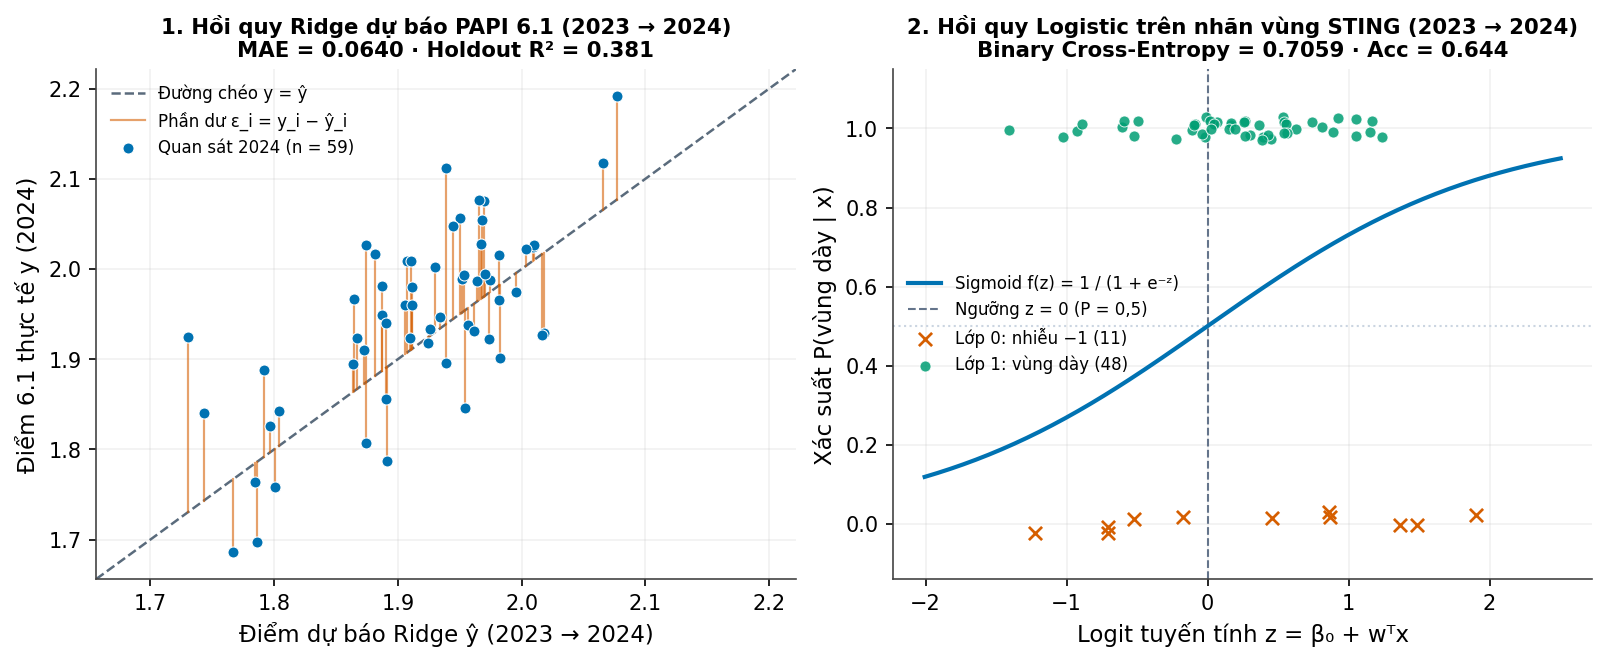

In [25]:
from sklearn.metrics import accuracy_score, f1_score, log_loss, r2_score
from scripts.supervised.predict_supervised import build_classification_pairs

y_true_reg = holdout.y.to_numpy()
y_pred_ridge = ridge.predict(holdout[REGRESSION_FEATURES].to_numpy())
ridge_r2 = r2_score(y_true_reg, y_pred_ridge)

clf_model = joblib.load(ROOT / "models/sup_classifier.joblib")
clf_pairs = build_classification_pairs(panel, features, params)
clf_hold = clf_pairs[clf_pairs.year_t == 2023]
Xc_te = clf_hold[REGRESSION_FEATURES].to_numpy()
yc_te = clf_hold["y"].to_numpy()
probs_te = clf_model.predict_proba(Xc_te)[:, 1]
logits_te = clf_model.decision_function(Xc_te)
preds_te = clf_model.predict(Xc_te)
bce_loss = log_loss(yc_te, probs_te)
clf_acc = accuracy_score(yc_te, preds_te)
clf_mf1 = f1_score(yc_te, preds_te, average="macro", labels=[0, 1], zero_division=0)
print(f"Hồi quy logistic trên tập 2024 ({len(yc_te)} tỉnh): "
      f"Binary Cross-Entropy = {bce_loss:.4f} | Acc = {clf_acc:.3f} | Macro-F1 = {clf_mf1:.3f}.")

with style_context():
    fig, (ax_reg, ax_log) = plt.subplots(1, 2, figsize=(10.6, 4.3), dpi=150, layout="constrained")

    lo_r = float(min(y_true_reg.min(), y_pred_ridge.min())) - 0.03
    hi_r = float(max(y_true_reg.max(), y_pred_ridge.max())) + 0.03
    ax_reg.plot([lo_r, hi_r], [lo_r, hi_r], "--", color="#5A6B7C", lw=1.2, label="Đường chéo y = ŷ", zorder=1)
    for idx_i, (yt, yp) in enumerate(zip(y_true_reg, y_pred_ridge, strict=True)):
        ax_reg.plot([yp, yp], [yp, yt], "-", color="#D55E00", alpha=0.58, lw=1.05,
                    label="Phần dư ε_i = y_i − ŷ_i" if idx_i == 0 else None, zorder=2)
    ax_reg.scatter(y_pred_ridge, y_true_reg, s=28, color=PALETTE["blue"], edgecolors="white", linewidths=0.5,
                   label="Quan sát 2024 (n = 59)", zorder=3)
    ax_reg.set_xlim(lo_r, hi_r)
    ax_reg.set_ylim(lo_r, hi_r)
    ax_reg.set_xlabel("Điểm dự báo Ridge ŷ (2023 → 2024)")
    ax_reg.set_ylabel("Điểm 6.1 thực tế y (2024)")
    ax_reg.set_title(f"1. Hồi quy Ridge dự báo PAPI 6.1 (2023 → 2024)\nMAE = {ridge_mae:.4f} · Holdout R² = {ridge_r2:.3f}", fontsize=10.2)
    ax_reg.grid(alpha=0.18)
    ax_reg.legend(loc="upper left", fontsize=8.0, framealpha=0.92)

    z_grid = np.linspace(float(logits_te.min()) - 0.6, float(logits_te.max()) + 0.6, 200)
    sig_grid = 1.0 / (1.0 + np.exp(-z_grid))
    ax_log.plot(z_grid, sig_grid, "-", color=PALETTE["blue"], lw=2.0, label="Sigmoid f(z) = 1 / (1 + e⁻ᶻ)", zorder=2)
    ax_log.axvline(0.0, color="#64748B", linestyle="--", lw=1.0, label="Ngưỡng z = 0 (P = 0,5)", zorder=1)
    ax_log.axhline(0.5, color="#CBD5E1", linestyle=":", lw=1.0, zorder=1)
    m0 = yc_te == 0
    m1 = yc_te == 1
    rng_j = np.random.default_rng(42)
    y0_j = rng_j.uniform(-0.03, 0.03, size=int(m0.sum()))
    y1_j = 1.0 + rng_j.uniform(-0.03, 0.03, size=int(m1.sum()))
    ax_log.scatter(logits_te[m0], y0_j, s=40, color="#D55E00", marker="x", linewidths=1.3,
                   label=f"Lớp 0: nhiễu −1 ({int(m0.sum())})", zorder=4)
    ax_log.scatter(logits_te[m1], y1_j, s=28, color=PALETTE["green"], alpha=0.85, edgecolors="white", linewidths=0.45,
                   label=f"Lớp 1: vùng dày ({int(m1.sum())})", zorder=4)
    ax_log.set_ylim(-0.14, 1.15)
    ax_log.set_xlabel("Logit tuyến tính z = β₀ + wᵀx")
    ax_log.set_ylabel("Xác suất P(vùng dày | x)")
    ax_log.set_title(f"2. Hồi quy Logistic trên nhãn vùng STING (2023 → 2024)\nBinary Cross-Entropy = {bce_loss:.4f} · Acc = {clf_acc:.3f}", fontsize=10.2)
    ax_log.grid(alpha=0.18)
    ax_log.legend(loc="center left", fontsize=8.0, framealpha=0.92)
    plt.show()

### Cải thiện phân loại mất cân bằng nhãn bằng `class_weight='balanced'`

Do cụm lớn chiếm đa số (~80%), mô hình mặc định dễ bỏ sót lớp rìa `0`. Nhóm kiểm chứng trực tiếp phương án cân bằng lớp trên **cùng 6 fold expanding-origin (2017–2022, 738 cặp)** và đối chiếu trên holdout 2023→2024 (59 tỉnh).

| Mô hình                       |   Macro-F1 CV (6 fold) |   Acc holdout |   Macro-F1 holdout |   Recall lớp 0 (nhiễu) |
|:------------------------------|-----------------------:|--------------:|-------------------:|-----------------------:|
| LR gốc (mặc định)             |                 0.4342 |        0.6441 |             0.5406 |                 0.4545 |
| LR balanced (C=0,3)           |                 0.4861 |        0.7458 |             0.595  |                 0.3636 |
| RF balanced (depth=6, leaf=2) |                 0.5238 |        0.7119 |             0.5686 |                 0.3636 |

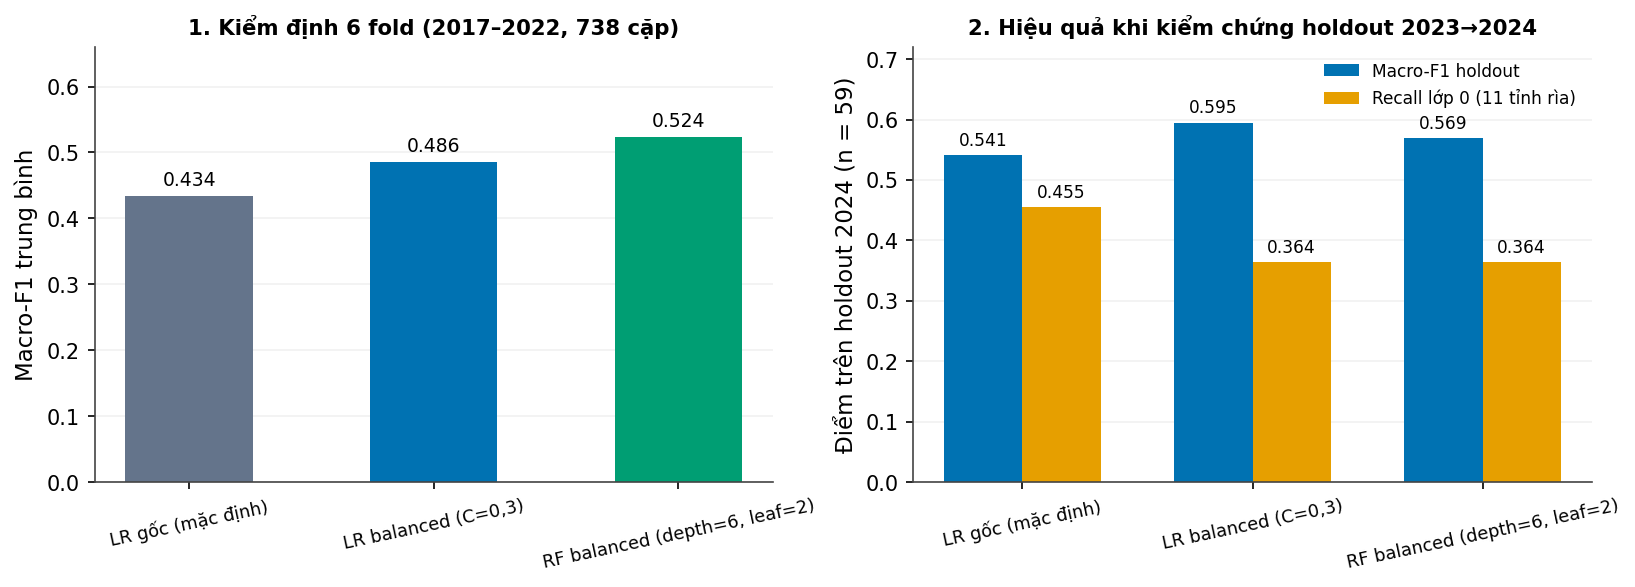

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score
from sklearn.pipeline import Pipeline
from scripts.supervised.predict_supervised import expanding_year_splits

clf_tr = clf_pairs[clf_pairs.year_t < 2023].reset_index(drop=True)
X_ctr, y_ctr = clf_tr[REGRESSION_FEATURES].to_numpy(), clf_tr["y"].to_numpy()
splits_cv = expanding_year_splits(clf_tr["year_t"].to_numpy(), y_ctr)

bal_specs = (
    ("LR gốc (mặc định)", lambda: Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=1.0, max_iter=3000, random_state=42))])),
    ("LR balanced (C=0,3)", lambda: Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=0.3, class_weight="balanced", max_iter=3000, random_state=42))])),
    ("RF balanced (depth=6, leaf=2)", lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, class_weight="balanced", random_state=42, n_jobs=1)),
)
bal_rows = []
for bname, bfactory in bal_specs:
    cv_mf1 = [
        f1_score(y_ctr[vi], bfactory().fit(X_ctr[ti], y_ctr[ti]).predict(X_ctr[vi]),
                 average="macro", labels=[0, 1], zero_division=0)
        for ti, vi in splits_cv
    ]
    bfit = bfactory().fit(X_ctr, y_ctr)
    bpred = bfit.predict(Xc_te)
    bal_rows.append((
        bname,
        float(np.mean(cv_mf1)),
        accuracy_score(yc_te, bpred),
        f1_score(yc_te, bpred, average="macro", labels=[0, 1], zero_division=0),
        recall_score(yc_te, bpred, pos_label=0),
    ))
bal_df = pd.DataFrame(bal_rows, columns=[
    "Mô hình", "Macro-F1 CV (6 fold)", "Acc holdout", "Macro-F1 holdout", "Recall lớp 0 (nhiễu)",
])
show_md(bal_df.round(4).to_markdown(index=False))

with style_context():
    fig_b, (ax_cv, ax_ho) = plt.subplots(1, 2, figsize=(10.8, 3.8), dpi=150, layout="constrained")
    x_pos = np.arange(len(bal_df))
    cols_b = ("#64748B", PALETTE["blue"], PALETTE["green"])
    bars1 = ax_cv.bar(x_pos, bal_df["Macro-F1 CV (6 fold)"], width=0.52, color=cols_b)
    ax_cv.bar_label(bars1, fmt="%.3f", padding=3, fontsize=9)
    ax_cv.set_xticks(x_pos, bal_df["Mô hình"], rotation=12, fontsize=8.5)
    ax_cv.set_ylim(0.0, 0.66)
    ax_cv.set_ylabel("Macro-F1 trung bình")
    ax_cv.set_title("1. Kiểm định 6 fold (2017–2022, 738 cặp)", fontsize=10.2)
    ax_cv.grid(axis="y", alpha=0.18)

    w_bar = 0.34
    b_mf1 = ax_ho.bar(x_pos - w_bar / 2, bal_df["Macro-F1 holdout"], width=w_bar, color=PALETTE["blue"], label="Macro-F1 holdout")
    b_rec = ax_ho.bar(x_pos + w_bar / 2, bal_df["Recall lớp 0 (nhiễu)"], width=w_bar, color=PALETTE["orange"], label="Recall lớp 0 (11 tỉnh rìa)")
    ax_ho.bar_label(b_mf1, fmt="%.3f", padding=3, fontsize=8.2)
    ax_ho.bar_label(b_rec, fmt="%.3f", padding=3, fontsize=8.2)
    ax_ho.set_xticks(x_pos, bal_df["Mô hình"], rotation=12, fontsize=8.5)
    ax_ho.set_ylim(0.0, 0.72)
    ax_ho.set_ylabel("Điểm trên holdout 2024 (n = 59)")
    ax_ho.set_title("2. Hiệu quả khi kiểm chứng holdout 2023→2024", fontsize=10.2)
    ax_ho.grid(axis="y", alpha=0.18)
    ax_ho.legend(loc="upper right", fontsize=8.2, framealpha=0.92)
    plt.show()

## Phụ lục C. Đối chiếu PCI và nghèo GSO

Nguồn đối chiếu gồm PCI của VCCI–USAID và tỷ lệ hộ nghèo cấp tỉnh GSO
PX-Web V14.47. Dữ liệu nghèo 2017–2019 lấy từ Niên giám Thống kê 2020/2021.
Kiểm định gồm dữ liệu gộp thô và dữ liệu đã trừ trung vị theo năm.

| section                 | group      |   year |   n |   mean |   median |   std |   min |   max |   note |
|:------------------------|:-----------|-------:|----:|-------:|---------:|------:|------:|------:|-------:|
| poverty_pooled_raw      | nhiễu (–1) |    nan | 144 |  9.872 |     6.6  | 9.937 |   0   |  42.3 |    nan |
| poverty_pooled_raw      | cụm 0      |    nan |   2 | 14.95  |    14.95 | 3.748 |  12.3 |  17.6 |    nan |
| poverty_pooled_raw      | cụm 1      |    nan |  10 |  4.55  |     3.25 | 3.641 |   1.2 |  12.1 |    nan |
| poverty_pooled_raw      | cụm 2      |    nan | 649 |  9.008 |     6.2  | 8.729 |   0   |  50.2 |    nan |
| poverty_pooled_demeaned | nhiễu (–1) |    nan | 144 |  2.124 |    -1.05 | 9.071 | -12.8 |  33.7 |    nan |
| poverty_pooled_demeaned | cụm 0      |    nan |   2 |  4.5   |     4.5  | 0.283 |   4.3 |   4.7 |    nan |
| poverty_pooled_demeaned | cụm 1      |    nan |  10 | -6.035 |    -6.2  | 2.848 |  -9   |   0.2 |    nan |
| poverty_pooled_demeaned | cụm 2      |    nan | 649 |  2.444 |     0    | 8.378 | -12.8 |  42.3 |    nan |

| section                 | group                                           |   n | note                              |
|:------------------------|:------------------------------------------------|----:|:----------------------------------|
| poverty_pooled_raw      | ANOVA F(3,801)                                  | 805 | F = 1.5376; p = 0.203             |
| poverty_pooled_raw      | Kruskal–Wallis                                  | 805 | H = 4.6670; p = 0.198             |
| poverty_pooled_raw      | eta squared                                     | 805 | eta² = 0.0057 (SS giữa / SS tổng) |
| poverty_pooled_demeaned | ANOVA F(3,801)                                  | 805 | F = 3.3629; p = 0.0183            |
| poverty_pooled_demeaned | Kruskal–Wallis                                  | 805 | H = 20.6285; p = 0.000126         |
| poverty_pooled_demeaned | eta squared                                     | 805 | eta² = 0.0124 (SS giữa / SS tổng) |
| test_mw_noise_vs_c2     | Mann–Whitney nhiễu vs cụm 2 (thô)               | 793 | U = 47464; p = 0.767              |
| test_mw_noise_vs_c2     | Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm) | 793 | U = 43978; p = 0.269              |


Gộp thô:                 H = 4.6670; p = 0.198
Đã trừ median trong năm: H = 20.6285; p = 0.000126
Mann–Whitney nhiễu vs cụm 2 (thô): U = 47464; p = 0.767
Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm): U = 43978; p = 0.269



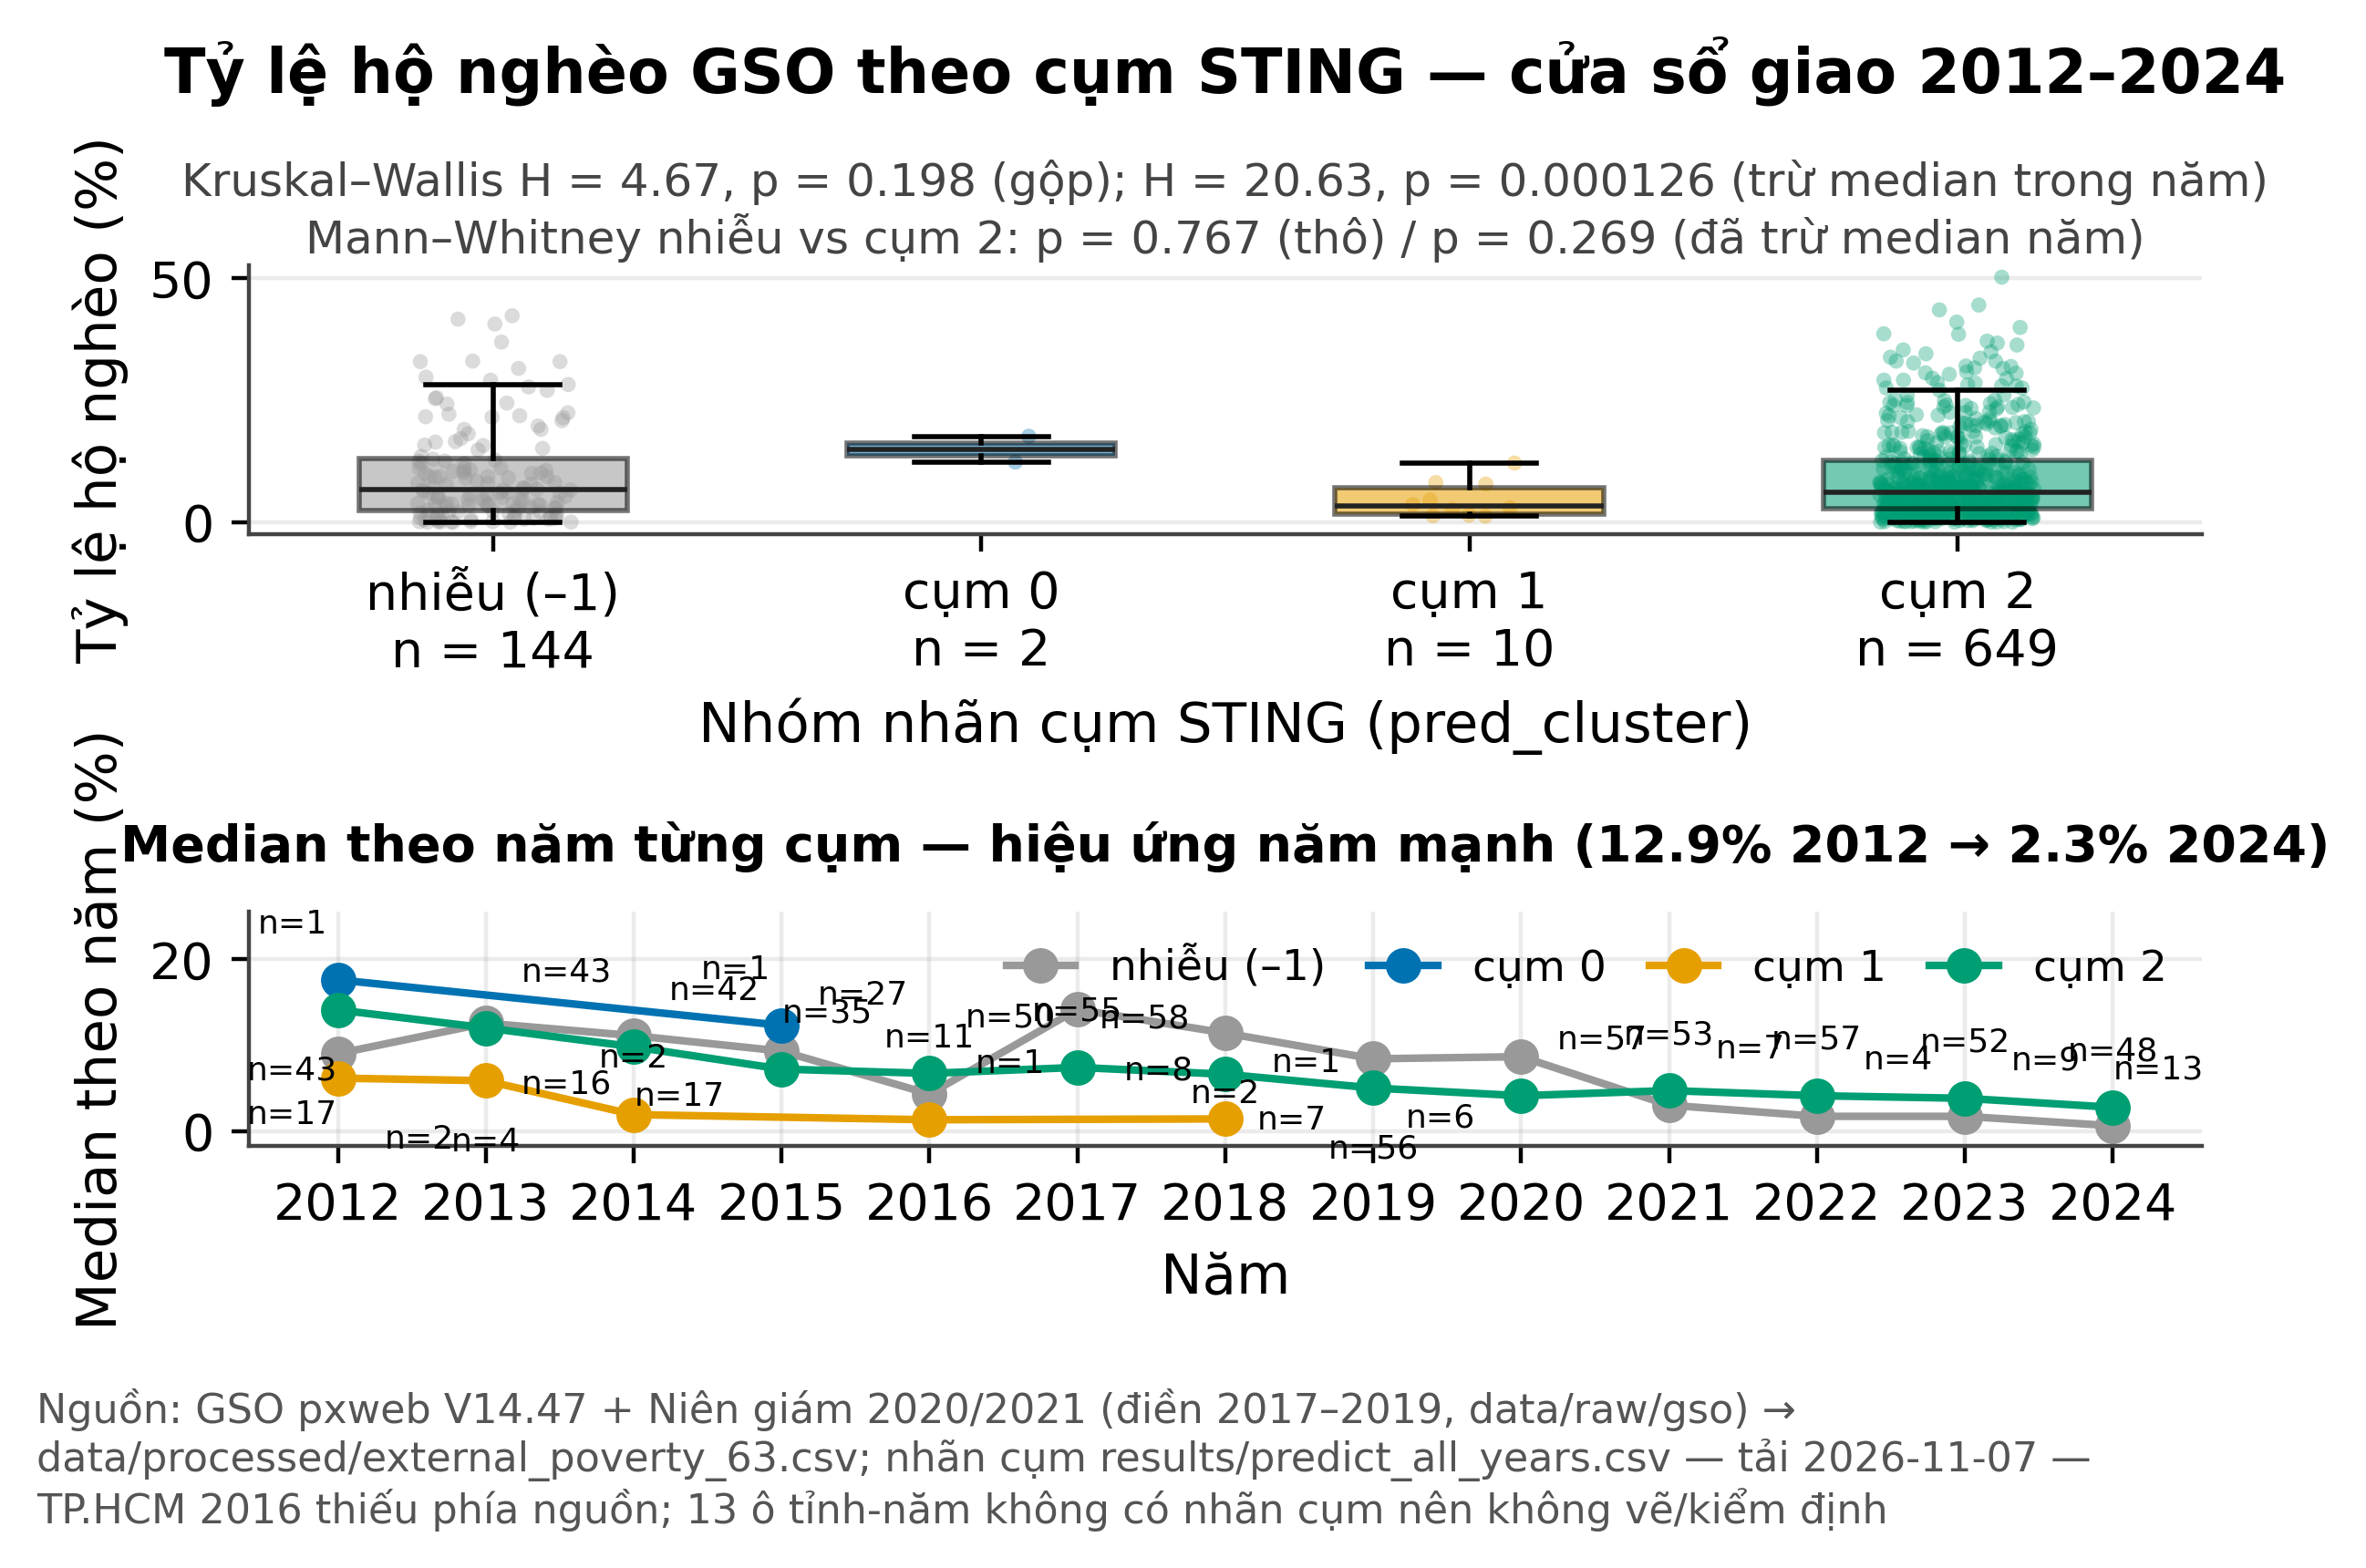

In [27]:
pov = pd.read_csv(ROOT / "results/poverty_validation.csv")

pooled_sections = ["poverty_pooled_raw", "poverty_pooled_demeaned", "test_mw_noise_vs_c2"]
pov_pool = pov[pov.section.isin(pooled_sections)].copy()
has_stats = pov_pool["mean"].notna() & pov_pool["mean"].astype(str).str.strip().ne("")
has_note = pov_pool["note"].notna() & pov_pool["note"].astype(str).str.strip().ne("")
show_md(pov_pool[has_stats].to_markdown(index=False))
print()
show_md(pov_pool[has_note][["section", "group", "n", "note"]].to_markdown(index=False))
print()

def _pov_note(section, group):
    return str(pov[(pov.section == section) & (pov.group == group)].iloc[0]["note"])

print("Gộp thô:                ", _pov_note("poverty_pooled_raw", "Kruskal–Wallis"))
print("Đã trừ median trong năm:", _pov_note("poverty_pooled_demeaned", "Kruskal–Wallis"))
for _, r in pov[pov.section == "test_mw_noise_vs_c2"].iterrows():
    print(f"{r['group']}: {r['note']}")
print()
display(Image(filename=str(ROOT / "results/figs/external_poverty_by_cluster.png")))